# Where temperature changes the algorithm an LLM writes: a demo of `method.py`

**Artifact `art_MZAfDPVhM6Ui`** (experiment, iteration 7, claim T) · model **Qwen/Qwen3-8B** (revision `b968826d`, bf16, thinking off)

**The question.** Is temperature the "creativity knob" of an LLM? On three coding units Qwen3-8B writes one of two known algorithms:
- **B3**, minimum spanning tree weight: Kruskal (the default, 0.80) or Prim with a heap (0.19);
- **A3**, trapped rain water: prefix/suffix maximum arrays (0.68) or two pointers (0.31);
- **B6**, valid anagram: sort and compare (0.77) or a fixed 26-slot count array (0.13).

**What the artifact does.**
1. **Locates the token where the algorithm is decided.** It resamples continuations from many prefixes of base programs, then applies Bayesian change points and a 20-continuation confirmation.
2. **Predicts, before sampling, how temperature and top-k move the algorithm share.** The predictions come from the logits at that token and were sha256-committed first.
3. **Tests the predictions in a same-seed sweep.** The same 50 uniform random streams are used in all 8 temperature × sampler cells.
4. **Links the fork to the task-specification states.** It does so with random pushes and a forced-state exchange (S4), and looks at the fork states in activation space (F7).

**Headline of the full run (verdict PARTIAL).**
- **One token decides the algorithm.** A single sampled token right after the canonical opening fixes it. On B3 the comment line `    # Kr…` gives Kruskal 100% and `    # Prim…` gives Prim 97%.
- **Temperature only reweights that token.**
  - Lowering T collapses the output onto the default: B3 Prim falls 0.40 → 0.06 from T 1.0 to 0.3 (exact McNemar 17:0).
  - Raising T above 1 adds nothing, and top-k 10 is token-identical to top-p 1.
  - No setting produced an algorithm outside the 2–3 known ones; only the phrasings multiply.
- **The task state does move the choice.** Exchanging task-spec states gives the minority algorithm on 30 of 30 seeds.

**What runs here.** `method.py` chains 12 stages.
- **GPU stages (not run).** Twins, the prefix-resampling scan, teacher forcing, the 1,200-program sweep and S4 took about 0.75 GPU-h on an RTX 4090. They need Qwen3-8B on a ≥ 20 GB GPU.
- **CPU-side code (run).** It is copied from `src/` with only path and data-loading changes, and runs on the data those GPU stages produced (`mini_demo_data.json`):

| section | original code | what it computes here |
|---|---|---|
| sampler, prediction function, CPU unit tests | `src/replay.py`, `src/predict.py`, `src/cpu7.py`, `src/commit7.py` | U4, U5, U7, U8 |
| fork location | `src/forks.py`, CPU part of `src/stages7.py` | change points, permutation test, refine jump, Fisher confirmation, mode rule |
| predictions | `src/predictions7.py` | H(A \| fork class) with bootstrap, fork margins, top-k report, S4(b) predictions from stored logits |
| same-seed replay | `src/replay.py`, `src/cfg7.py` | each program's fork-token draw from its own PCG64 stream |
| scoring | `src/analysis_T.py` | Tests 1–3, verdict and the ideas × phrasings table on 100 B3 sweep programs |
| figures | `src/figures7.py` | F1, F2, F4, F7 (4096-d fork-state geometry), predicted vs observed |

In [1]:
import subprocess, sys
def _pip(*a): subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *a])

# loguru -- NOT on Colab, always install (method.py and src/cfg7.py log with it)
_pip('loguru==0.7.3')

# numpy, scipy, pandas, matplotlib -- pre-installed on Colab, install locally only (at Colab's exact versions)
if 'google.colab' not in sys.modules:
    _pip('numpy==2.0.2', 'scipy==1.16.3', 'pandas==2.2.2', 'matplotlib==3.10.0')

In [2]:
from __future__ import annotations

# ---- method.py ----
import subprocess
import sys
import time
from pathlib import Path

from loguru import logger

# ---- src/cfg7.py, src/replay.py, src/predict.py, src/forks.py, src/commit7.py, src/predictions7.py,
#      src/analysis_T.py, src/figures7.py ----
import ast
import hashlib
import itertools
import json
import math
import os
from collections import Counter, defaultdict
from datetime import datetime, timezone
from typing import Any, Iterable

import matplotlib.pyplot as plt
import numpy as np
from scipy.special import gammaln, logsumexp
from scipy.stats import binom, fisher_exact, spearmanr

# ---- notebook additions ----
import base64                        # decodes the bf16 activation arrays stored in mini_demo_data.json
import shutil                        # resets the notebook's scratch folder
from types import SimpleNamespace    # stands in for the module names the original code calls (replay., PR., FK., CM.)

import pandas as pd                  # result tables

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)

In [3]:
GITHUB_DATA_URL = "https://raw.githubusercontent.com/ai-inventor-papers/ai-invention-295f8e-prompt-bans-substitute-not-just-subtract/fork/run_jSassd-YWLVC/round-7/experiment-35/demo/mini_demo_data.json"
import http.client
import json
import urllib.request
from pathlib import Path

def load_data():
    try:
        with urllib.request.urlopen(GITHUB_DATA_URL, timeout=15) as response:
            return json.loads(response.read().decode())
    # Network errors, timeouts, a placeholder URL, bad JSON, a cut-off response.
    except (OSError, ValueError, http.client.HTTPException) as e:
        print("GitHub data unavailable, using local mini_demo_data.json:", e)
    local = Path("mini_demo_data.json")
    if local.exists(): return json.loads(local.read_text())
    raise FileNotFoundError("Could not load mini_demo_data.json")

In [4]:
data = load_data()
meta = data["metadata"]
examples = data["datasets"][0]["examples"]
print(meta["description"])
print(f"\ndataset '{data['datasets'][0]['dataset']}': {len(examples)} programs")
print("selection:", meta["demo_selection"])

GitHub data unavailable, using local mini_demo_data.json: HTTP Error 404: Not Found
Curated demo input for 'Where temperature changes the algorithm an LLM writes' (iteration 7, claim T, Qwen/Qwen3-8B@b968826d, bf16, thinking off). One dataset (100 B3 same-seed sweep programs) plus the fork tables, committed predictions, S4(b) logits, fork-state geometry and full-run results that the artifact's CPU-side code reads.

dataset 'sweep': 100 programs
selection: {'units': ['B3'], 'samplers': ['p1'], 'temperatures': [0.3, 0.7, 1.0, 1.3], 'templates': ['W1', 'W2', 'W3', 'W4', 'W5'], 'sweep_slots': [20, 21, 22, 23, 24], 'note': 'the full sweep has slots 20-29 (50 per cell), both samplers and all 3 units'}


## Configuration

Every tunable size is set here. The comment on each line gives its full-run value.

- **Resampling depths.** The bootstrap, permutation and unit-test counts set only resampling depth. The whole notebook runs in about a minute on a CPU at the full-run values.
- **Data-capped values.** `N_SWEEP_SLOTS` and `DEMO_SAMPLERS` are capped by what `mini_demo_data.json` holds:
  - the full sweep has 10 slots × 5 templates = 50 programs per cell, for both samplers, on all three units;
  - the demo file holds slots 20–24 of B3 under top-p 1, i.e. 25 programs per temperature and 100 in all.
  - Top-k 10 programs are left out: in the full run all 600 of them were token-identical to their top-p 1 twins.

In [5]:
# ---- demo scale (the full-run value of each parameter is in its comment) ----
N_SWEEP_SLOTS = 5          # sweep slots per template, from slot 20 (full run: 10 -> slots 20-29, N = 50 per cell);
                           # mini_demo_data.json holds slots 20-24, so 5 (N = 25 per cell) is this demo's maximum
DEMO_SAMPLERS = {"p1": 0}  # sampler id -> top_k (full run: {"p1": 0, "k10": 10}); the demo file holds top-p 1 only
N_BOOT_H = 1000            # bootstrap replicates of H(A | fork class), Test 1 (full run: 1000)
N_BOOT_DROP = 2000         # slot-bootstrap replicates of the T 1.0 -> 0.3 minority drop, Test 2 (full run: 2000)
N_PERM = 500               # label permutations of the change-point sensitivity statistic (full run: 500)
N_RUNS_U4 = 200            # synthetic series in unit test U4 of the change-point rule (full run: 200)
HILL1_REPS = 300           # rarefaction draws of the correct-only Hill-1 idea diversity (full run: 300)
HILL1_DEPTH = 25           # rarefaction depth, programs per draw (full run: 25)

DEMO_DIR = Path("demo_out")   # scratch folder for the files this notebook writes (commitment chain, result JSONs)

## The pipeline: `method.py`

`method.py` runs 12 stages in order. Each stage resumes from its files, and every GPU stage runs in its own process.

The next cell holds `method.py`'s stage table and driver exactly as written, with two changes:
- `ROOT` is the notebook folder, and the log-file sink is dropped (stdout only);
- `main()` is **defined but not called**, because its GPU stages need the Qwen3-8B weights (16 GB in bf16) on a CUDA GPU.

The printout maps each stage to what this notebook does with it.

| stages | what they do in the full run |
|---|---|
| `vendor`, `prompts` | sha256-copy the prior inputs; build the twin, ban, forced and padding prompts (templates W1–W5, e.g. *"Do not use house for this task."* before the task) |
| `gputests`, `twins`, `cputests`, `commit0` | engine checks; 100 twin programs per unit at T 1.0; CPU unit tests; COMMIT #0 (protocol and thresholds) |
| `forkscan`, `commit1` | prefix resampling, then change points, refinement and confirmation; COMMIT #1 (the forks) |
| `predict`, `commit2` | teacher-forced logits; fork-token conditionals P(A \| t); cell predictions; COMMIT #2, before any temperature sample |
| `generate` | the same-seed sweep (3 units × 4 T × 2 samplers × 50 slots); S4(a) pushes; S4(b) exchange; F7 states; the collapsed-task check |
| `finalize` | blind judges; committed scoring (`analysis_T.py`); re-derivation; post-hoc checks; novelty audit; figures; outputs |

In [6]:
# ---- method.py (verbatim apart from the marked lines; main() is defined but not called) ----
ROOT = Path.cwd()                                   # was: Path(__file__).resolve().parent
PY = sys.executable
SRC = ROOT / "src"
sys.path.insert(0, str(SRC))

logger.remove()
logger.add(sys.stdout, level="INFO", format="{time:HH:mm:ss}|{level:<7}|{message}")
# (ROOT / "logs").mkdir(exist_ok=True)                                            # dropped: stdout only
# logger.add(str(ROOT / "logs" / "method.log"), rotation="30 MB", level="DEBUG")

UNITS = "B3,A3,B6"
STAGES = {
    "vendor": [PY, str(SRC / "vendor_inputs.py")],
    "gputests": [PY, str(SRC / "gpu7.py"), "tests"],
    "twins": [PY, str(SRC / "gpu7.py"), "twins", "--units", "B3,A3,B6,T2,T03,T1,T10"],
    "cputests": [PY, str(SRC / "cpu7.py"), "tests"],
    "commit0": [PY, str(SRC / "cpu7.py"), "commit0"],
    "forkscan": [PY, str(SRC / "gpu7.py"), "forkscan", "--units", UNITS],
    "predict": [PY, str(SRC / "gpu7.py"), "predict,s4predict,collapsed_margins", "--units", UNITS],
    "commit2": [PY, str(SRC / "predictions7.py"), "commit2"],
    "generate": [PY, str(SRC / "gpu7.py"), "sweep,s4b,s4a,geometry,collapsed", "--units", UNITS],
}
FINALIZE = [
    [PY, str(SRC / "novelty7.py"), "dep"],
    [PY, str(SRC / "novelty7.py"), "judge"],
    [PY, str(SRC / "analysis_T.py")],
    [PY, str(SRC / "rederive.py")],
    [PY, str(SRC / "posthoc7.py")],
    [PY, str(SRC / "novelty7.py"), "audit"],
    [PY, "-c", "import sys; sys.path.insert(0, 'src'); import novelty7; novelty7.regate()"],
    [PY, str(SRC / "views7.py")],
    [PY, str(SRC / "figures7.py")],
    [PY, str(SRC / "report7.py")],
    [PY, str(SRC / "outputs7.py")],
    [PY, str(SRC / "commit7.py")],
]
ORDER = ["vendor", "prompts", "gputests", "twins", "cputests", "commit0", "forkscan", "commit1", "predict", "commit2",
         "generate", "finalize"]


def run(cmd: list[str]) -> None:
    t0 = time.time()
    logger.info("$ " + " ".join(Path(c).name if c.startswith(str(ROOT)) else c for c in cmd))
    pr = subprocess.run(cmd, cwd=ROOT)
    if pr.returncode != 0:
        raise RuntimeError(f"stage failed ({pr.returncode}): {cmd}")
    logger.info(f"  done in {time.time() - t0:.0f}s")


def prompts() -> None:
    from transformers import AutoTokenizer

    import prompts7 as P7
    from cfg7 import RESULTS_DIR, model_path, write_json
    tok = AutoTokenizer.from_pretrained(model_path())
    rows = P7.write_prompts(tok)
    chk = P7.u3_checks(tok, rows)
    write_json(RESULTS_DIR / "u3_prompt_checks.json", chk)
    if not chk["all_pass_required"]:
        raise RuntimeError("U3 prompt checks failed")


def commit1() -> None:
    import cpu7
    logger.info(cpu7.commit1())


@logger.catch(reraise=True)
def main() -> None:
    what = sys.argv[1] if len(sys.argv) > 1 else "all"
    stages = ORDER if what == "all" else what.split(",")
    for st in stages:
        logger.info(f"=== {st} ===")
        if st == "prompts":
            prompts()
        elif st == "commit1":
            commit1()
        elif st == "finalize":
            for cmd in FINALIZE:
                run(cmd)
        elif st in STAGES:
            run(STAGES[st])
        else:
            raise ValueError(f"unknown stage {st}; known: {ORDER}")


# main()   # not called in this notebook -- see the stage map below

# ---- notebook addition: what this notebook does with each stage ----
WHERE = {
    "vendor": "not run: copies + sha256-hashes the prior artifacts",
    "prompts": "not run (Qwen3 tokenizer); each example's 'input' is its prompt",
    "gputests": "not run (GPU engine checks)",
    "twins": "not run (GPU); its openings + fork tables are in the data",
    "cputests": "RE-RUN: U4, U5, U7, U8",
    "commit0": "not run; its frozen thresholds are THRESH below",
    "forkscan": "RE-RUN, CPU part: change points .. mode rule",
    "commit1": "not run; the scan it hashes feeds the fork section",
    "predict": "RE-RUN, CPU part: H(A|C), margins, top-k, S4(b)",
    "commit2": "RE-RUN in miniature: a fresh sha256 chain",
    "generate": "not run (GPU); 100 of its sweep programs = the data",
    "finalize": "RE-RUN, scoring part: Tests 1-3, verdict, 1a-c, figs",
}
for st in ORDER:
    if st in STAGES:
        what = " ".join(Path(c).name if c.startswith(str(ROOT)) else c for c in STAGES[st][1:])
    elif st == "finalize":
        what = f"{len(FINALIZE)} scripts: " + ", ".join(Path(c[1]).stem for c in FINALIZE if c[1] != "-c")
    else:
        what = f"{st}() in method.py"
    print(f"{st:<9} | {what[:60]:<60} | {WHERE[st]}")

vendor    | vendor_inputs.py                                             | not run: copies + sha256-hashes the prior artifacts
prompts   | prompts() in method.py                                       | not run (Qwen3 tokenizer); each example's 'input' is its prompt
gputests  | gpu7.py tests                                                | not run (GPU engine checks)
twins     | gpu7.py twins --units B3,A3,B6,T2,T03,T1,T10                 | not run (GPU); its openings + fork tables are in the data
cputests  | cpu7.py tests                                                | RE-RUN: U4, U5, U7, U8
commit0   | cpu7.py commit0                                              | not run; its frozen thresholds are THRESH below
forkscan  | gpu7.py forkscan --units B3,A3,B6                            | RE-RUN, CPU part: change points .. mode rule
commit1   | commit1() in method.py                                       | not run; the scan it hashes feeds the fork section
predict   | gpu7.py predict,s4p

## Constants and helpers (`src/cfg7.py`)

Copied from `src/cfg7.py`, with two changes:
- the artifact's folder constants (`results/`, `predictions/`, `cache/`, `commitments.log`) point into `DEMO_DIR`;
- three demo-scale overrides from the config cell are applied at the end.

Two conventions matter below.

- **Same-seed sampling (CRN).** Every program slot owns one stream of uniforms, one per generated token: `u_stream(key)` is PCG64 seeded with a sha256 of the key `('iter7T', unit, template, slot)`. A sweep slot keeps its stream in all 8 temperature × sampler cells. Any difference between the cells therefore comes from the sampler transform alone.
- **The committed thresholds `THRESH`.** They were frozen in COMMIT #0, before any decisive sample:
  - Test 1: H(A | fork class) ≤ 0.3 bits;
  - Test 2: drop ≥ 0.15, MAE ≤ 0.10, and the T 1.0 → 1.3 deviation ≤ 0.10;
  - Test 3: collapsed margins ≥ 4 nats.

In [7]:
# ---- src/cfg7.py (excerpt; the folder constants are re-pointed at DEMO_DIR) ----
shutil.rmtree(DEMO_DIR, ignore_errors=True)        # notebook: start every run from an empty scratch folder
RESULTS_DIR = DEMO_DIR / "results"                 # was: ROOT / "results"
PRED_DIR = DEMO_DIR / "predictions"                # was: ROOT / "predictions"
CACHE_DIR = DEMO_DIR / "cache"                     # was: ROOT / "cache"
COMMITS = DEMO_DIR / "commitments.log"             # was: ROOT / "commitments.log"
for _d in (RESULTS_DIR, PRED_DIR, CACHE_DIR):
    _d.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------------------------------------------ model
MODEL_ID = "Qwen/Qwen3-8B"
MODEL_REVISION = "b968826d9c46dd6066d109eabc6255188de91218"
N_LAYERS = 36
D_MODEL = 4096
IM_END = 151645
ENDOFTEXT = 151643
TEMPLATE_TAIL = "<|im_end|>\n<|im_start|>assistant\n<think>\n\n</think>\n\n"
PRECISION = "bf16"
U_LEN = 1536

# ------------------------------------------------------------------------------------------------ units
TEMPLATES = ("W1", "W2", "W3", "W4", "W5")
BAN_TEMPLATES: dict[str, tuple[str, str]] = {  # (ban, neutral) protocol v2 W1-W5, verbatim
    "W1": ("Do not use {X} for this task.", "Do not use {N} for this task."),
    "W2": ("Your solution must not rely on {X}.", "Your solution must not rely on {N}."),
    "W3": ("Avoid {X} entirely.", "Avoid {N} entirely."),
    "W4": ("{X} is not allowed here.", "{N} is not allowed here."),
    "W5": ("Write a correct solution that does not use {X}.", "Write a correct solution that does not use {N}."),
}
PAD_FILLER = " ."
MIXED = ("B3", "A3", "B6")
COLLAPSED = ("T1", "T2", "T10", "T03")
UNITS: dict[str, dict[str, Any]] = {
    "B3": {"name": "minimum spanning tree weight", "default": "kruskal",
           "catalogue": ["kruskal", "prim_heap", "prim_array", "boruvka"], "a_min_plan": "prim_heap",
           "display": {"kruskal": "Kruskal's algorithm", "prim_heap": "Prim's algorithm with a heap",
                       "prim_array": "Prim's algorithm with an array scan", "boruvka": "Boruvka's algorithm"},
           "record_share": 0.34, "max_new": 768, "batch": 32, "src": "exp26"},
    "A3": {"name": "trapped rain water", "default": "prefix_suffix_max",
           "catalogue": ["two_pointers", "prefix_suffix_max", "monotonic_stack", "peak_split"],
           "a_min_plan": "two_pointers",
           "display": {"two_pointers": "two pointers", "prefix_suffix_max": "prefix and suffix maximum arrays",
                       "monotonic_stack": "a monotonic stack", "peak_split": "splitting at the highest bar"},
           "record_share": 0.36, "max_new": 640, "batch": 40, "src": "exp25"},
    "B6": {"name": "valid anagram", "default": "sort_compare",
           "catalogue": ["sort_compare", "hash_count", "fixed_count_array"], "a_min_plan": "hash_count",
           "display": {"sort_compare": "sorting both strings", "hash_count": "a hash map of letter counts",
                       "fixed_count_array": "a fixed 26-slot count array"},
           "record_share": 0.24, "max_new": 384, "batch": 50, "src": "exp26"},
}
COLLAPSED_INFO = {"T1": {"default": "bfs", "y": "dfs", "max_new": 640, "fence": "path"},
                  "T2": {"default": "dijkstra", "y": "bf_spfa", "max_new": 512, "fence": "path"},
                  "T10": {"default": "union_find", "y": "bfs", "max_new": 384, "fence": "bench"},
                  "T03": {"default": "full_sort", "y": "quickselect", "max_new": 384, "fence": "bench"}}

# ------------------------------------------------------------------------------------------------ design
TEMPS = (0.3, 0.7, 1.0, 1.3)
SAMPLERS = {"p1": 0, "k10": 10}          # sampler id -> top_k (0 = off); top-p is 1 everywhere
TWIN_SLOTS = tuple(range(0, 20))
SWEEP_SLOTS = tuple(range(20, 30))
S4A_SLOTS = (0, 1)
S4B_SLOTS = tuple(range(0, 6))
SCAN_STEP = 4
SCAN_MAX = 96
SCAN_HORIZON = 160
N_SCAN = 8
N_CONFIRM = 20
CONT_BATCH = 64
V_BLOCKS = list(range(12, 24))
DIRECTIONS = tuple(range(9101, 9109))
ALPHA_PUSH = 2.0
BOOT_SEED = 20261022
N_BOOT = 1000

# committed thresholds (Part F); frozen in commit #0
THRESH = {
    "test1_H_bits_pass": 0.3, "test1_H_bits_disconfirm": 0.5, "test1_units_needed": 2,
    "test2_drop_min": 0.15, "test2_mae_max": 0.10, "test2_13_tol": 0.10, "test2_units_needed": 2,
    "test2_mae_disconfirm": 0.2, "test3_margin_nats": 4.0, "fork_pchange": 0.9, "fork_share_jump_bp": 0.4,
    "confirm_jump": 0.5, "confirm_fisher_p": 0.01, "control_move_max": 0.2, "calib_fisher_p": 0.01,
    "oc_agree": 0.95, "oc_cover": 0.85, "onetoken_frac": 2 / 3, "secondary_bonferroni": 0.05 / 7,
}


# ------------------------------------------------------------------------------------------------ utils
def utc_now() -> str:
    return datetime.now(timezone.utc).strftime("%Y-%m-%dT%H:%M:%S.%fZ")


def sha256_text(s: str) -> str:
    return hashlib.sha256(s.encode("utf-8")).hexdigest()


def sha256_file(p: Path) -> str:
    h = hashlib.sha256()
    with open(p, "rb") as fh:
        for chunk in iter(lambda: fh.read(1 << 20), b""):
            h.update(chunk)
    return h.hexdigest()


def stable_seed(*parts: Any) -> int:
    """Deterministic 63-bit seed from arbitrary parts (sha256 of their '|'-joined repr) -- exp8/exp17 convention."""
    return int(hashlib.sha256("|".join(str(p) for p in parts).encode()).hexdigest(), 16) % (2 ** 63)


def u_stream(*key: Any, n: int = U_LEN) -> np.ndarray:
    return np.random.Generator(np.random.PCG64(stable_seed(*key))).random(n)


def _json_default(o: Any) -> Any:
    if isinstance(o, np.integer):
        return int(o)
    if isinstance(o, np.floating):
        return None if not np.isfinite(o) else float(o)
    if isinstance(o, np.ndarray):
        return o.tolist()
    if isinstance(o, np.bool_):
        return bool(o)
    if isinstance(o, Path):
        return str(o)
    if isinstance(o, (set, frozenset)):
        return sorted(o)
    raise TypeError(f"not JSON serialisable: {type(o)}")


def read_json(p: Path) -> Any:
    return json.loads(Path(p).read_text())


def write_json(p: Path, obj: Any) -> None:
    p = Path(p)
    p.parent.mkdir(parents=True, exist_ok=True)
    tmp = p.with_suffix(p.suffix + ".tmp")
    tmp.write_text(json.dumps(obj, indent=1, default=_json_default))
    tmp.replace(p)


# ---- notebook: the demo-scale overrides from the config cell ----
SAMPLERS = DEMO_SAMPLERS                             # full run: {"p1": 0, "k10": 10}
SWEEP_SLOTS = tuple(range(20, 20 + N_SWEEP_SLOTS))   # full run: tuple(range(20, 30))
N_BOOT = N_BOOT_H                                    # full run: 1000

for u in MIXED:
    U0 = meta["units"][u]
    print(f"{u}: {UNITS[u]['name']:<30} default {U0['D']:<18} minority A_min {U0['A_min']:<18} cats {U0['cats']}")
print("\nCRN stream of sweep slot B3|W1|20, first 5 uniforms:", np.round(u_stream("iter7T", "B3", "W1", 20)[:5], 6))
print("sweep slots used:", SWEEP_SLOTS, "| samplers:", SAMPLERS, "| temperatures:", TEMPS)

B3: minimum spanning tree weight   default kruskal            minority A_min prim_heap          cats ['kruskal', 'prim_heap', 'prim_array', 'boruvka', 'other']
A3: trapped rain water             default prefix_suffix_max  minority A_min two_pointers       cats ['two_pointers', 'prefix_suffix_max', 'monotonic_stack', 'peak_split', 'other']
B6: valid anagram                  default sort_compare       minority A_min fixed_count_array  cats ['sort_compare', 'hash_count', 'fixed_count_array', 'other']

CRN stream of sweep slot B3|W1|20, first 5 uniforms: [0.609196 0.816825 0.059837 0.241863 0.218652]
sweep slots used: (20, 21, 22, 23, 24) | samplers: {'p1': 0} | temperatures: (0.3, 0.7, 1.0, 1.3)


## The sampler (`src/replay.py`, verbatim)

At every step the engine turns the bf16 logits into one token:
1. `p = softmax(z / T)` in float64;
2. an optional top-k mask;
3. the cumulative sum in **token-id order**: the token is the first one whose CDF reaches the slot's uniform `u`.

`replay.py` is the artifact's independent float64 copy of that transform. It matched the engine on 10,000 of 10,000 steps.

The CDF runs in token-id order, not by probability. So when T changes, the token intervals shift, and the same `u` can land on a different token. That is how one seed can write Kruskal at T 0.3 and Prim at T 1.0.

In [8]:
# ---- src/replay.py (verbatim) ----
"""replay.pick(z, u, T, k): an independent float64 numpy re-implementation of the engine's per-step transform
(engine5.step_probs5 + engine_v4._inverse_cdf):
    p = softmax(z / T)                          (float64; z = the bf16 logits widened to float64)
    top-k: p[p < k-th largest p] = 0             (ties at the k-th value kept, exactly as the engine)
    cdf = cumsum(p) in TOKEN-ID order; cdf /= cdf[-1]
    token = first index with cdf >= u            (torch.searchsorted, right=False), clamped to V - 1
The token-id order makes the coupling across temperatures exact in marginals but NOT monotone in T, so per-slot
predictions must use pick(), never a sorted CDF.
"""


def probs(z: np.ndarray, T: float, k: int = 0) -> np.ndarray:
    x = np.asarray(z, dtype=np.float64) / float(T)
    x = x - x.max()
    p = np.exp(x)
    p /= p.sum()
    if k and k > 0:
        kth = np.partition(p, -k)[-k]
        p = np.where(p < kth, 0.0, p)
    return p


def pick(z: np.ndarray, u: float, T: float, k: int = 0) -> int:
    p = probs(z, T, k)
    cdf = np.cumsum(p)
    cdf = cdf / cdf[-1]
    t = int(np.searchsorted(cdf, u, side="left"))
    return min(t, len(p) - 1)


def dist(z: np.ndarray, T: float, k: int = 0) -> np.ndarray:
    """The normalised sampling distribution of one step (kept mass renormalised)."""
    p = probs(z, T, k)
    return p / p.sum()


replay = SimpleNamespace(probs=probs, pick=pick, dist=dist)   # notebook: the module name the other code calls

# a toy 4-token vocabulary: the same uniform u picks a different token id as T changes
z_toy = np.array([2.0, 0.5, 2.6, 1.0])
print("toy logits", z_toy, "| u = 0.45")
for T in TEMPS:
    print(f"  T {T}: p = {np.round(replay.dist(z_toy, T), 3)} -> token {replay.pick(z_toy, 0.45, T)}")

toy logits [2.  0.5 2.6 1. ] | u = 0.45
  T 0.3: p = [0.119 0.001 0.876 0.004] -> token 2
  T 0.7: p = [0.269 0.032 0.635 0.065] -> token 2
  T 1.0: p = [0.293 0.065 0.534 0.108] -> token 2
  T 1.3: p = [0.297 0.094 0.471 0.138] -> token 2


## The committed prediction function (`src/predict.py`, verbatim)

For one template, the predicted share of algorithm A at temperature T and sampler κ (full vocabulary, or top-k 10) has three parts.

- **Staying on the opening.** `w(c) = ∏ᵢ π_{T,κ}(o_{c,i} | o_{c,<i})` is the probability of staying on opening cluster c. It comes from the teacher-forced logits along the opening.
- **The fork mix.** `F(c, A) = Σ_t π_{T,κ}(t | O_c) · P̂(A | O_c + t) + residual mass · P̂(A | residual bin)`.
- **The cell prediction.** `P̂(A) = Σ_c w(c) · F(c, A) + (1 − Σ_c w(c)) · q_rest(A)`.

`P̂(A | t)` is measured once, at T = 1, from continuations after each fork token t. It carries over to other temperatures because a single token's class nearly fixes the algorithm. Test 1 checks exactly that one-token concentration.

The cell also holds the artifact's own unit tests of this function, which run in the `cputests` stage below:
- **U5:** a synthetic binary fork with margin 0.575 nats. Its minority share must follow 1 / (1 + e^{m/T}), and top-k 10 must remove a rank-11 minority token.
- **U8:** a path probability on a two-step tree.

In [9]:
# ---- src/predict.py (verbatim; `import replay` is the SimpleNamespace above) ----
"""Committed prediction functions (Part D4/D5), pure numpy over teacher-forced fp32 logits.

  pi_{T,kappa}(t | prefix) = softmax(z / T) over all tokens (kappa = full) or over the 10 largest logits (top10)
  w_{T,kappa}(c)   = prod_i pi_{T,kappa}(o_{c,i} | o_{c,<i})                       (probability of staying on O_c)
  F_{T,kappa}(c,A) = sum_t pi_{T,kappa}(t | O_c) Phat(A | O_c + t) + residual mass x Phat(A | residual bin)
  Phat_{T,kappa}(A) = sum_c w(c) F(c,A) + (1 - sum_c w(c)) q_rest(A)
Phat(A | t) is estimated from T = 1 continuations (the one-token concentration assumption carries it to other T).
"""


def dist(z: np.ndarray, T: float, k: int) -> np.ndarray:
    return replay.dist(z, T, k)


def seq_logprob(Z: np.ndarray, toks: list[int], T: float, k: int) -> float:
    """sum_i log pi_{T,k}(toks[i] | row i of Z); -inf if a token is truncated away."""
    s = 0.0
    for z, t in zip(Z, toks):
        p = dist(z, T, k)[t]
        if p <= 0:
            return -math.inf
        s += math.log(p)
    return s


def fork_mix(z: np.ndarray, phat: dict[int, np.ndarray], resid: np.ndarray, T: float, k: int) -> dict[str, Any]:
    """F(c, .) at one fork node: expanded tokens use their own Phat, the remaining mass uses the residual bin."""
    p = dist(z, T, k)
    toks = list(phat)
    mass = np.array([p[t] for t in toks])
    F = np.zeros_like(resid, dtype=float)
    for m, t in zip(mass, toks):
        F += m * phat[t]
    rest = max(0.0, 1.0 - float(mass.sum()))
    F += rest * resid
    return {"F": F, "expanded_mass": float(mass.sum()), "residual_mass": rest}


def cell_prediction(clusters: list[dict[str, Any]], q_rest: np.ndarray, T: float, k: int) -> dict[str, Any]:
    """clusters: [{'Z_open': [len_O, V] logits predicting o_1..o_|O| (row i predicts o_i), 'O': ids,
    'z_fork': [V], 'phat': {tok: [C]}, 'resid': [C]}] for ONE template."""
    tot = np.zeros_like(q_rest, dtype=float)
    w_sum = 0.0
    parts = []
    for c in clusters:
        lw = seq_logprob(c["Z_open"], c["O"], T, k) if len(c["O"]) else 0.0
        w = math.exp(lw) if lw > -math.inf else 0.0
        fm = fork_mix(c["z_fork"], c["phat"], c["resid"], T, k)
        tot += w * fm["F"]
        w_sum += w
        parts.append({"w": w, "F": fm["F"].tolist(), "residual_mass": fm["residual_mass"]})
    w_sum = min(w_sum, 1.0)
    tot += (1.0 - w_sum) * q_rest
    return {"P": tot, "on_opening": w_sum, "parts": parts}


def binary_closed_form(m: float, T: float) -> float:
    """Minority probability of a binary fork with margin m nats at temperature T: 1 / (1 + exp(m / T))."""
    return 1.0 / (1.0 + math.exp(m / T))


def margin_nats(z: np.ndarray, d_tokens: list[int]) -> float:
    """m = log P_1(D-class tokens) - log P_1(non-D tokens) at T = 1."""
    p = dist(z, 1.0, 0)
    pd = float(sum(p[t] for t in d_tokens))
    pd = min(max(pd, 1e-300), 1.0)
    pn = max(1.0 - pd, 1e-300)
    return math.log(pd) - math.log(pn)


def u5_test() -> dict[str, Any]:
    """U5: synthetic binary fork with margin 0.575 nats and a fully shared opening."""
    V = 50
    z = np.full(V, -1e4)
    z[3], z[7] = 0.575, 0.0                   # D token 3, minority token 7
    phat = {3: np.array([1.0, 0.0]), 7: np.array([0.0, 1.0])}
    cl = [{"Z_open": np.zeros((0, V)), "O": [], "z_fork": z, "phat": phat, "resid": np.array([0.5, 0.5])}]
    got = {T: float(cell_prediction(cl, np.array([0.5, 0.5]), T, 0)["P"][1]) for T in (0.3, 1.0, 1.3)}
    want = {0.3: 0.128, 1.0: 0.36, 1.3: 0.391}
    # top-k 10 with the minority token at rank 11: 10 stronger tokens
    z2 = np.full(V, -1e4)
    z2[3], z2[7] = 0.575, 0.0
    for t in range(20, 30):
        z2[t] = 0.3
    phat2 = {3: np.array([1.0, 0.0]), 7: np.array([0.0, 1.0])} | {t: np.array([1.0, 0.0]) for t in range(20, 30)}
    cl2 = [{"Z_open": np.zeros((0, V)), "O": [], "z_fork": z2, "phat": phat2, "resid": np.array([0.5, 0.5])}]
    top10 = float(cell_prediction(cl2, np.array([0.5, 0.5]), 1.0, 10)["P"][1])
    ok = all(abs(got[T] - want[T]) < 0.0015 for T in want) and top10 == 0.0
    return {"got": got, "want": want, "closed_form": {T: binary_closed_form(0.575, T) for T in want},
            "top10_rank11_minority": top10, "pass": ok}


def u8_test() -> dict[str, Any]:
    """U8: path probability on a synthetic tree: two steps with known probabilities 0.2 and 0.5 -> 0.1."""
    V = 6
    z1 = np.log(np.array([0.2, 0.8, 1e-12, 1e-12, 1e-12, 1e-12]))
    z2 = np.log(np.array([0.5, 0.25, 0.25, 1e-12, 1e-12, 1e-12]))
    lp = seq_logprob(np.stack([z1, z2]), [0, 0], 1.0, 0)
    m = margin_nats(z1, [1])
    return {"path_prob": math.exp(lp), "want": 0.1, "margin": m, "margin_want": math.log(0.8 / 0.2),
            "pass": abs(math.exp(lp) - 0.1) < 1e-6 and abs(m - math.log(4)) < 1e-6}


PR = SimpleNamespace(dist=dist, seq_logprob=seq_logprob, fork_mix=fork_mix, cell_prediction=cell_prediction,
                     binary_closed_form=binary_closed_form, margin_nats=margin_nats, u5_test=u5_test, u8_test=u8_test)

## Fork-location functions (`src/forks.py`, verbatim)

- **C1 `opening()`.** A token trie over the 100 twin programs. From the root it follows the most populous child while that subtree still holds ≥ 2 programs of each algorithm. The resulting trunk is the *canonical opening* O; large side branches become extra opening clusters.
- **C4 `change_points()`.** For each base program, a Bayesian single-change-point model over the prefix lengths k:
  - Dirichlet(1)-multinomial segment likelihoods, a uniform prior on the change location τ, and prior 0.5 on change vs no change;
  - a change is detected if P(change) ≥ 0.9 and the program's own-class share jumps by ≥ 0.4;
  - each resulting segment is searched again, recursively.
- **Sensitivity and confirmation.**
  - `perm_stat()` is a permutation-calibrated max-jump statistic.
  - `jump_position()` finds the largest single-token jump in the refined window.
  - `confirm()` is the 20-continuation Fisher test at f − 1 vs f, with control positions f − 9 and f + 8 that must not move.

In [10]:
# ---- src/forks.py (verbatim) ----
"""Fork location (Part C), pure functions.

C1 canonical opening: a token trie over the twin programs' generated ids; from the root follow the most populous child
   while its subtree still holds >= 2 programs of D and >= 2 of A_min. The trunk O ends at the first node whose children
   separate the classes (or where the condition fails). Opening clusters: other branches leaving the trunk that hold
   >= 15% of the programs get their own trunk O_c (same rule inside the branch).
C4 change points: per base path, a Bayesian single-change-point model over the scanned prefix lengths:
   Dirichlet(1)-multinomial segment likelihoods, a uniform prior on tau, prior 0.5 on change vs no change; a change is
   detected if P(change | data) >= 0.9 and the base path's own class share differs by >= 0.4 across tau (MAP).
   Recursion on each segment, at most 3 change points. Sensitivity: a permutation-calibrated max-share-jump statistic.
"""


# ------------------------------------------------------------------------------------------------ C1 opening
def _walk(progs: list[tuple[list[int], str]], start: list[int], D: str, A: str) -> list[int]:
    path = list(start)
    sub = [(g, c) for g, c in progs if g[:len(path)] == path]
    while True:
        nxt = Counter(g[len(path)] for g, c in sub if len(g) > len(path))
        if not nxt:
            return path
        tok, _ = nxt.most_common(1)[0]
        child = [(g, c) for g, c in sub if len(g) > len(path) and g[len(path)] == tok]
        nD = sum(c == D for _, c in child)
        nA = sum(c == A for _, c in child)
        if nD >= 2 and nA >= 2:
            path.append(tok)
            sub = child
        else:
            return path


def opening(progs: list[tuple[list[int], str]], D: str, A: str, min_cluster: float = 0.15,
            max_clusters: int = 3) -> dict[str, Any]:
    """progs: (generated ids, label). Returns the trunk O, coverage and opening clusters."""
    n = len(progs)
    O = _walk(progs, [], D, A)
    cov = sum(g[:len(O)] == O for g, _ in progs) / n
    clusters = [{"id": "c0", "O": O, "n": int(round(cov * n)), "cov": cov}]
    if cov < 0.6:
        # branches leaving the trunk before its end with >= 15% of programs
        for i in range(len(O)):
            pre = O[:i]
            sub = [(g, c) for g, c in progs if g[:i] == pre and len(g) > i]
            for tok, m in Counter(g[i] for g, _ in sub).most_common():
                if tok == O[i] or m < min_cluster * n:
                    continue
                Oc = _walk(progs, pre + [tok], D, A)
                ccov = sum(g[:len(Oc)] == Oc for g, _ in progs) / n
                if ccov >= min_cluster and len(clusters) < max_clusters:
                    clusters.append({"id": f"c{len(clusters)}", "O": Oc, "n": int(round(ccov * n)), "cov": ccov})
    return {"O": O, "len_O": len(O), "cov": cov, "clusters": clusters}


def cluster_of(g: list[int], clusters: list[dict[str, Any]]) -> str | None:
    best = None
    for c in clusters:
        if g[:len(c["O"])] == c["O"] and (best is None or len(c["O"]) > len(best["O"])):
            best = c
    return best["id"] if best else None


# ------------------------------------------------------------------------------------------------ C4 change points
def dm_loglik(counts: np.ndarray, alpha: float = 1.0) -> float:
    counts = np.asarray(counts, dtype=float)
    C = len(counts)
    N = counts.sum()
    return float(gammaln(C * alpha) - gammaln(C * alpha + N) + np.sum(gammaln(alpha + counts) - gammaln(alpha)))


def single_cp(series: np.ndarray) -> dict[str, Any]:
    """series: [K, C] label counts per scanned position. Returns P(change), the tau posterior (tau = index of the
    first position of the second segment, 1..K-1) and the MAP tau."""
    K = series.shape[0]
    if K < 2:
        return {"p_change": 0.0, "tau": None, "post": []}
    tot = series.sum(0)
    ll0 = dm_loglik(tot)
    cums = np.cumsum(series, 0)
    lls = np.array([dm_loglik(cums[t - 1]) + dm_loglik(tot - cums[t - 1]) for t in range(1, K)])
    ll1 = logsumexp(lls) - math.log(K - 1)
    p = 1.0 / (1.0 + math.exp(min(700.0, ll0 - ll1)))
    post = np.exp(lls - logsumexp(lls))
    return {"p_change": p, "tau": int(np.argmax(post)) + 1, "post": post.tolist()}


def share(counts: np.ndarray, j: int) -> float:
    s = counts.sum()
    return float(counts[j] / s) if s > 0 else float("nan")


def change_points(series: np.ndarray, own: int, p_min: float = 0.9, jump_min: float = 0.4,
                  max_cp: int = 3) -> list[dict[str, Any]]:
    """Recursive single-change-point detection on [lo, hi) segments; returns detected change points with their
    absolute position index, posterior and own-class share before/after."""
    found: list[dict[str, Any]] = []

    def rec(lo: int, hi: int) -> None:
        if len(found) >= max_cp or hi - lo < 3:
            return
        r = single_cp(series[lo:hi])
        if r["tau"] is None:
            return
        t = lo + r["tau"]
        before = share(series[lo:t].sum(0), own)
        after = share(series[t:hi].sum(0), own)
        ok = r["p_change"] >= p_min and abs(after - before) >= jump_min
        if not ok:
            return
        found.append({"tau_idx": t, "p_change": r["p_change"], "share_before": before, "share_after": after,
                      "jump": after - before, "segment": [lo, hi], "post": r["post"]})
        rec(lo, t)
        rec(t, hi)
    rec(0, series.shape[0])
    return sorted(found, key=lambda d: d["tau_idx"])


def perm_stat(series: np.ndarray, own: int, n_perm: int = 500, seed: int = 0) -> dict[str, Any]:
    """Sensitivity: max over tau of |own share before - after|, calibrated by permuting individual continuation
    labels across positions (500 permutations, iteration-1 style)."""
    K, C = series.shape

    def stat(s: np.ndarray) -> float:
        best = 0.0
        cs = np.cumsum(s, 0)
        tot = s.sum(0)
        for t in range(1, K):
            a, b = cs[t - 1], tot - cs[t - 1]
            if a.sum() == 0 or b.sum() == 0:
                continue
            best = max(best, abs(a[own] / a.sum() - b[own] / b.sum()))
        return best
    obs = stat(series)
    labels = np.repeat(np.tile(np.arange(C), K), series.reshape(-1).astype(int))
    pos_sizes = series.sum(1).astype(int)
    rng = np.random.default_rng(seed)
    ge = 0
    for _ in range(n_perm):
        perm = rng.permutation(labels)
        s = np.zeros_like(series)
        i = 0
        for k, m in enumerate(pos_sizes):
            for c in perm[i:i + m]:
                s[k, c] += 1
            i += m
        ge += stat(s) >= obs - 1e-12
    return {"stat": obs, "p_perm": (ge + 1) / (n_perm + 1)}


# ------------------------------------------------------------------------------------------------ C5/C6
def jump_position(shares: dict[int, float]) -> int | None:
    """Largest absolute share jump between consecutive prefix lengths: returns j (prefix length after the jump)."""
    ks = sorted(shares)
    best, bj = -1.0, None
    for a, b in zip(ks, ks[1:]):
        if b != a + 1 or np.isnan(shares[a]) or np.isnan(shares[b]):
            continue
        d = abs(shares[b] - shares[a])
        if d > best:
            best, bj = d, b
    return bj


def confirm(n_pre: tuple[int, int], n_post: tuple[int, int], ctrl_pre: tuple[int, int] | None,
            ctrl_post: tuple[int, int] | None, jump_min: float = 0.5, p_max: float = 0.01,
            ctrl_max: float = 0.2) -> dict[str, Any]:
    """(own-class count, total) at f-1 and f, and at the controls f-9 (vs f-1) and f+8 (vs f)."""
    s_pre = n_pre[0] / max(n_pre[1], 1)
    s_post = n_post[0] / max(n_post[1], 1)
    p = fisher_exact([[n_pre[0], n_pre[1] - n_pre[0]], [n_post[0], n_post[1] - n_post[0]]])[1]
    c1 = abs(ctrl_pre[0] / max(ctrl_pre[1], 1) - s_pre) if ctrl_pre else None
    c2 = abs(ctrl_post[0] / max(ctrl_post[1], 1) - s_post) if ctrl_post else None
    ok_ctrl = all(c is None or c < ctrl_max for c in (c1, c2))
    return {"share_pre": s_pre, "share_post": s_post, "jump": s_post - s_pre, "fisher_p": float(p),
            "ctrl_pre_move": c1, "ctrl_post_move": c2,
            "confirmed": bool(abs(s_post - s_pre) >= jump_min and p < p_max and ok_ctrl)}


def jeffreys(k: int, n: int, a: float = 0.05) -> tuple[float, float]:
    from scipy.stats import beta
    lo = 0.0 if k == 0 else float(beta.ppf(a / 2, k + 0.5, n - k + 0.5))
    hi = 1.0 if k == n else float(beta.ppf(1 - a / 2, k + 0.5, n - k + 0.5))
    return lo, hi


def entropy_bits(p: np.ndarray) -> float:
    p = np.asarray(p, dtype=float)
    p = p[p > 0]
    return float(-(p * np.log2(p)).sum()) if len(p) else 0.0


FK = SimpleNamespace(opening=opening, cluster_of=cluster_of, dm_loglik=dm_loglik, single_cp=single_cp, share=share,
                     change_points=change_points, perm_stat=perm_stat, jump_position=jump_position, confirm=confirm,
                     jeffreys=jeffreys, entropy_bits=entropy_bits)

## The sha256 commitment chain (`src/commit7.py`, verbatim)

The predictions were committed before the data that tests them existed:
- **COMMIT #0:** the protocol and thresholds;
- **COMMIT #1:** the forks;
- **COMMIT #2:** every prediction plus the scoring code's hashes, before the first temperature sample.

`commit()` writes a commit file and appends `UTC  name  sha256(file)  chain` to `commitments.log`, where `chain = sha256(previous chain + file sha256)`. `verify()` recomputes every link, so editing any committed file afterwards breaks the chain.

In [11]:
# ---- src/commit7.py (verbatim; COMMITS / PRED_DIR / ROOT come from the cfg7 cell) ----
"""sha256 commitment chain (iteration-6 commit6 convention): each commit file's sha256 is appended to
commitments.log as 'UTC  name  sha256(file)  chain', chain = sha256(previous chain + file sha256).
verify() recomputes every link; a tampered file or line breaks the chain (U7)."""

GENESIS = "0" * 64


def _lines(log: Path = COMMITS) -> list[list[str]]:
    if not log.exists():
        return []
    return [l.split("  ") for l in log.read_text().splitlines() if l.strip()]


def commit(name: str, payload: dict[str, Any], log: Path = COMMITS, pred_dir: Path = PRED_DIR) -> dict[str, str]:
    p = pred_dir / f"{name}.json"
    if p.exists() and any(l[1] == name for l in _lines(log)):
        raise FileExistsError(f"commit {name} already exists; amendments need a new name")
    write_json(p, {"commit": name, "utc": utc_now(), **payload})
    h = sha256_file(p)
    prev = _lines(log)[-1][3] if _lines(log) else GENESIS
    chain = hashlib.sha256((prev + h).encode()).hexdigest()
    with open(log, "a") as fh:
        fh.write(f"{utc_now()}  {name}  {h}  {chain}\n")
    return {"name": name, "sha256": h, "chain": chain}


def verify(log: Path = COMMITS, pred_dir: Path = PRED_DIR) -> dict[str, Any]:
    prev = GENESIS
    out = {"ok": True, "n": 0, "bad": []}
    for utc, name, h, chain in _lines(log):
        p = pred_dir / f"{name}.json"
        h2 = sha256_file(p) if p.exists() else None
        c2 = hashlib.sha256((prev + h).encode()).hexdigest()
        if h2 != h or c2 != chain:
            out["ok"] = False
            out["bad"].append(name)
        prev = chain
        out["n"] += 1
    return out


def code_hashes(files: list[str]) -> dict[str, str]:
    return {f: sha256_file(ROOT / f) for f in files if (ROOT / f).exists()}


def self_test(tmp: Path) -> dict[str, Any]:
    """U7: commit, verify, tamper detection on a scratch chain."""
    tmp.mkdir(parents=True, exist_ok=True)
    log = tmp / "commitments_test.log"
    for f in tmp.glob("*.json"):
        f.unlink()
    log.unlink(missing_ok=True)
    commit("t0", {"x": 1}, log, tmp)
    commit("t1", {"y": 2}, log, tmp)
    ok = verify(log, tmp)["ok"]
    p = tmp / "t0.json"
    d = json.loads(p.read_text())
    d["x"] = 2
    p.write_text(json.dumps(d))
    tampered = verify(log, tmp)
    return {"verify_clean": ok, "tamper_detected": not tampered["ok"], "bad": tampered["bad"]}


CM = SimpleNamespace(commit=commit, verify=verify, code_hashes=code_hashes, self_test=self_test)

## Stage `cputests`: the CPU unit tests (`src/cpu7.py`)

Four of the artifact's eight unit tests run here as they did in the full run. The other four need resources the notebook lacks: U1 and U6 need the frozen labellers and reference programs, U2 the GPU, and U3 the tokenizer.

| test | what passes |
|---|---|
| U4 | the change-point rule finds a 0.3 → 0.9 share jump in ≥ 90% of synthetic 25-position series, with ≤ 5% false alarms on flat series |
| U5, U8 | the prediction-function tests above |
| U7 | the sha256 chain verifies clean and detects a tampered commit file |

With `N_RUNS_U4` at its minimum the U4 rates are coarse, so it may fail by chance. At the full-run value of 200 it passes.

In [12]:
# ---- src/cpu7.py: u4_changepoint (verbatim; n_runs from the config cell) ----
def u4_changepoint(n_runs: int = N_RUNS_U4) -> dict[str, Any]:     # was: n_runs: int = 200
    rng = np.random.default_rng(11)
    K, n = 25, 8
    hits = fps = 0
    for _ in range(n_runs):
        tau = int(rng.integers(5, 20))
        p = np.where(np.arange(K) < tau, 0.3, 0.9)
        S = np.stack([np.bincount(rng.random(n) < pk, minlength=2)[::-1] for pk in p]).astype(float)
        cps = FK.change_points(S, 0, 0.9, 0.4)
        hits += any(c["tau_idx"] == tau or abs(c["tau_idx"] - tau) <= 1 for c in cps)
        S0 = np.stack([np.bincount(rng.random(n) < 0.5, minlength=2)[::-1] for _ in range(K)]).astype(float)
        fps += bool(FK.change_points(S0, 0, 0.9, 0.4))
    return {"detect_rate_0.6_jump": hits / n_runs, "false_positive_rate": fps / n_runs,
            "pass": hits / n_runs >= 0.9 and fps / n_runs <= 0.05}


# ---- run_tests() of src/cpu7.py, CPU-only part (U1/U6 need the labellers, U2 the GPU, U3 the tokenizer) ----
t0 = time.time()
tests_cpu: dict[str, Any] = {"utc": utc_now()}
tests_cpu["U4"] = u4_changepoint()
tests_cpu["U5"] = PR.u5_test()
tests_cpu["U7"] = CM.self_test(CACHE_DIR / "tmp" / "commit_test")
tests_cpu["U8"] = PR.u8_test()
write_json(RESULTS_DIR / "tests_cpu.json", tests_cpu)

u4, u5, u7, u8 = (tests_cpu[k] for k in ("U4", "U5", "U7", "U8"))
print(f"U4 change-point rule ({N_RUNS_U4} runs): detection {u4['detect_rate_0.6_jump']:.3f} (>= 0.9), "
      f"false positives {u4['false_positive_rate']:.3f} (<= 0.05) -> {'PASS' if u4['pass'] else 'FAIL'}")
print(f"U5 binary fork, minority share at T 0.3/1.0/1.3: {[round(v, 4) for v in u5['got'].values()]} "
      f"(want {list(u5['want'].values())}; closed form {[round(v, 4) for v in u5['closed_form'].values()]}); "
      f"top-k 10 with the minority at rank 11 -> {u5['top10_rank11_minority']} -> {'PASS' if u5['pass'] else 'FAIL'}")
print(f"U7 commitment chain: clean verify {u7['verify_clean']}, tamper detected {u7['tamper_detected']} "
      f"(bad: {u7['bad']}) -> {'PASS' if u7['verify_clean'] and u7['tamper_detected'] else 'FAIL'}")
print(f"U8 path probability {u8['path_prob']:.6f} (want 0.1), margin {u8['margin']:.6f} (want log 4 = "
      f"{u8['margin_want']:.6f}) -> {'PASS' if u8['pass'] else 'FAIL'}")
print(f"[{time.time() - t0:.1f}s]")

U4 change-point rule (200 runs): detection 0.995 (>= 0.9), false positives 0.000 (<= 0.05) -> PASS
U5 binary fork, minority share at T 0.3/1.0/1.3: [0.1282, 0.3601, 0.3912] (want [0.128, 0.36, 0.391]; closed form [0.1282, 0.3601, 0.3912]); top-k 10 with the minority at rank 11 -> 0.0 -> PASS
U7 commitment chain: clean verify True, tamper detected True (bad: ['t0']) -> PASS
U8 path probability 0.100000 (want 0.1), margin 1.386294 (want log 4 = 1.386294) -> PASS
[0.4s]


## Stage `forkscan` (CPU part): where is the algorithm decided?

**The GPU part (full run).**
- **Base programs.** It took 12 base programs per unit (8 for B6), twins of both algorithms, mostly on the canonical opening.
- **Scan.** For each, it forced the first k generated tokens and sampled 8 continuations at T = 1, for k = 0, 4, …, 96 (to 160 where needed). An opening classifier labelled every continuation, which gives a `series` of label counts per k.
- **Refine.** Around a detected change it scanned every single k.
- **Confirm.** At the refined fork f it drew 20 continuations at f − 1, f, f − 9 and f + 8.

**This cell (CPU part).** It re-runs the CPU half of `stage_forkscan` (`src/stages7.py`) on those stored counts:
- `change_points` and `perm_stat` on every series, and the primary change point;
- `jump_position` on the refined shares, and `confirm` on the confirmation counts;
- the `at_O_plus_1` flag;
- the unit's mode rule: **ONE-TOKEN** if ≥ 2/3 of the confirmed on-opening forks sit at |O| + 1.

**Expected.**
- Every number equals the committed `forks.json`. The permutation p matches once `N_PERM` = 500.
- The confirmed forks of on-opening base paths sit exactly at **|O| + 1**, the first token after the canonical opening. On B3 that is the word after `    # ` (` Kr` vs ` Prim`).

In [13]:
# ---- src/stages7.py: cats / cat_index (verbatim) ----
def cats(unit: str) -> list[str]:
    return UNITS[unit]["catalogue"] + ["other"]


def cat_index(unit: str, lab: str) -> int:
    c = cats(unit)
    return c.index(lab) if lab in c else len(c) - 1


# ---- stage_forkscan (src/stages7.py), CPU part; the continuation counts come from the committed forks.json ----
F = meta["forks"]
t0 = time.time()
forks_demo = {}
for u in MIXED:
    bps = F[u]["base_paths"]
    op = F[u]["opening"]
    info_b = {}
    # refine step: change points + permutation sensitivity on the scan series
    for bp in bps:
        st = F[u]["per_base_path"][bp["bid"]]
        ks = st["ks"]                                     # was: S = series_of(u, bp["bid"], ("scan",)); ks = sorted(S)
        arr = np.array(st["series"], dtype=float)         # was: arr = np.stack([S[k] for k in ks])
        own = cat_index(u, bp["cls"])
        cps = FK.change_points(arr, own, THRESH["fork_pchange"], THRESH["fork_share_jump_bp"])
        perm = FK.perm_stat(arr, own, N_PERM, seed=stable_seed("perm", bp["bid"]) % 2 ** 31)   # was: n_perm 500
        prim = max(cps, key=lambda c: abs(c["jump"])) if cps else None
        info_b[bp["bid"]] = {"ks": ks, "series": arr.tolist(), "cps": [{k: v for k, v in c.items() if k != "post"}
                                                                      | {"k_tau": ks[c["tau_idx"]]} for c in cps],
                             "primary": None if prim is None else ks[prim["tau_idx"]], "perm": perm,
                             "own_share": [float(a[own] / max(a.sum(), 1)) for a in arr]}
    # confirm step: the single-token jump inside the refined window, then the 20-continuation Fisher test
    for bp in bps:
        ib = info_b[bp["bid"]]
        if ib["primary"] is None:
            continue
        sh = {int(k): v for k, v in F[u]["per_base_path"][bp["bid"]]["refine_shares"].items()}  # was: from series_of
        f = FK.jump_position(sh)
        ib["refine_shares"] = sh
        ib["f"] = f
    for bp in bps:
        ib = info_b[bp["bid"]]
        if ib.get("f") is None:
            ib["confirmed"] = False
            continue
        st = F[u]["per_base_path"][bp["bid"]]
        f = ib["f"]
        cnt = {int(k): tuple(v) for k, v in st["confirm_counts"].items()}   # was: from series_of(..., ("confirm",))
        c = FK.confirm(cnt[f - 1], cnt[f], cnt.get(max(0, f - 9)) if max(0, f - 9) != f - 1 else None,
                       cnt.get(min(bp["len"] - 1, f + 8)) if min(bp["len"] - 1, f + 8) != f else None,
                       THRESH["confirm_jump"], THRESH["confirm_fisher_p"], THRESH["control_move_max"])
        ib.update({"confirm": c, "confirmed": c["confirmed"], "confirm_counts": {str(k): v for k, v in cnt.items()},
                   "fork_token": st["fork_token"],                          # was: tok.decode([bp["token_ids"][f - 1]])
                   "at_O_plus_1": bool(bp["on_O"] and f == op["len_O"] + 1)})
    conf_on = [ib for b, ib in info_b.items() if ib.get("confirmed") and next(x for x in bps if x["bid"] == b)["on_O"]]
    mode = "ONE-TOKEN" if conf_on and sum(ib["at_O_plus_1"] for ib in conf_on) >= THRESH["onetoken_frac"] * len(conf_on) \
        else "TREE"
    forks_demo[u] = {"mode": mode, "per_base_path": info_b,
                     "n_confirmed": sum(bool(ib.get("confirmed")) for ib in info_b.values()),
                     "n_confirmed_on_O": len(conf_on), "n_at_O_plus_1": sum(ib["at_O_plus_1"] for ib in conf_on)}
print(f"fork scan re-derived in {time.time() - t0:.1f}s (N_PERM = {N_PERM})\n")

# ---- notebook: demo vs committed, per base path and per unit ----
bp_rows = []
for u in MIXED:
    for bp in F[u]["base_paths"]:
        ib, st = forks_demo[u]["per_base_path"][bp["bid"]], F[u]["per_base_path"][bp["bid"]]
        cf = ib.get("confirm") or {}
        bp_rows.append({"unit": u, "base path": bp["bid"], "on O": bp["on_O"],
                        "change at k": ib["primary"], "committed k": st["primary"], "fork f": ib.get("f"),
                        "fork token": repr(ib.get("fork_token")) if ib.get("f") else "",
                        "share f-1 -> f": f"{cf['share_pre']:.2f} -> {cf['share_post']:.2f}" if cf else "",
                        "Fisher p": cf.get("fisher_p"), "confirmed": ib["confirmed"],
                        "committed confirmed": bool(st.get("confirmed")), "at |O|+1": ib.get("at_O_plus_1", ""),
                        "perm p": round(ib["perm"]["p_perm"], 4), "committed perm p": round(st["perm"]["p_perm"], 4)})
bp_df = pd.DataFrame(bp_rows)
display(bp_df[bp_df["change at k"].notna()])
print(f"{len(bp_df)} base paths: change points equal to the committed ones on "
      f"{int((bp_df['change at k'].fillna(-1) == bp_df['committed k'].fillna(-1)).sum())}; confirmations equal on "
      f"{int((bp_df['confirmed'] == bp_df['committed confirmed']).sum())}; permutation p equal on "
      f"{int((bp_df['perm p'] == bp_df['committed perm p']).sum())} (needs N_PERM = 500)\n")
unit_df = pd.DataFrame([{"unit": u, "|O|": F[u]["opening"]["len_O"], "O covers": F[u]["opening"]["cov"],
                         "opening ends with": repr(F[u]["opening"]["O_text"][-24:]),
                         "confirmed": forks_demo[u]["n_confirmed"], "confirmed on O": forks_demo[u]["n_confirmed_on_O"],
                         "at |O|+1": forks_demo[u]["n_at_O_plus_1"], "mode": forks_demo[u]["mode"],
                         "committed mode": F[u]["mode"], "calibration Fisher p": round(F[u]["calibration"]["fisher_p"], 3)}
                        for u in MIXED])
display(unit_df)

fork scan re-derived in 2.5s (N_PERM = 500)



,unit,base path,on O,change at k,committed k,fork f,fork token,share f-1 -> f,Fisher p,confirmed,committed confirmed,at |O|+1,perm p,committed perm p
6,B3,B3_prim_heap_W1_4,True,64.0,64.0,62.0,' Prim',0.30 -> 1.00,3.340382e-06,True,True,True,0.002,0.002
7,B3,B3_prim_heap_W3_5,True,64.0,64.0,62.0,' Prim',0.10 -> 0.95,5.819515e-08,True,True,True,0.002,0.002
8,B3,B3_prim_heap_W5_4,True,64.0,64.0,62.0,' Prim',0.40 -> 0.90,2.199641e-03,True,True,True,0.002,0.002
9,B3,B3_prim_heap_W2_15,True,68.0,68.0,65.0,' to',0.95 -> 1.00,1.000000e+00,False,False,False,0.002,0.002
10,B3,B3_prim_heap_W5_3,False,64.0,64.0,62.0,' Prim',0.30 -> 0.95,3.931372e-05,True,True,False,0.002,0.002
11,B3,B3_prim_heap_W1_0,False,64.0,64.0,62.0,' Prim',0.10 -> 0.90,5.295890e-07,True,True,False,0.002,0.002
15,A3,A3_prefix_suffix_max_W5_5,True,20.0,20.0,17.0,'\n',0.70 -> 0.70,1.000000e+00,False,False,False,0.004,0.004
18,A3,A3_two_pointers_W3_13,True,20.0,20.0,19.0,' left',0.10 -> 0.70,2.443618e-04,False,False,True,0.002,0.002
19,A3,A3_two_pointers_W1_13,True,20.0,20.0,19.0,' left',0.15 -> 0.90,3.357952e-06,True,True,True,0.002,0.002
20,A3,A3_two_pointers_W5_2,False,20.0,20.0,17.0,'\n \n',0.40 -> 0.60,3.430672e-01,False,False,False,0.002,0.002


32 base paths: change points equal to the committed ones on 32; confirmations equal on 32; permutation p equal on 32 (needs N_PERM = 500)



,unit,|O|,O covers,opening ends with,confirmed,confirmed on O,at |O|+1,mode,committed mode,calibration Fisher p
0,B3,61,0.51,"'v].append((u, w))\n\n #'",5,3,3,ONE-TOKEN,ONE-TOKEN,0.575
1,A3,18,0.48,'ht:\n return 0\n ',2,1,1,ONE-TOKEN,ONE-TOKEN,0.195
2,B6,23,0.78,' return False\n ',1,1,1,ONE-TOKEN,ONE-TOKEN,0.195


### F1: the outcome curves and their change-point posteriors (`src/figures7.py`)

**Top figure.** Each line is one base program: its own-class share among the 8 continuations sampled after forcing its first k tokens.
- Coloured lines are minority-algorithm programs; grey lines are default-algorithm programs. Solid lines are on the canonical opening.
- The dashed line marks |O| + 1, and the triangles mark the refined forks (filled = confirmed).
- **Reading.** Before the fork, a minority program's continuations still fall back to the default most of the time. Right after it, they all follow the program.

**Bottom figure.** The single-change-point posterior over k for every base program.

The plotting code is `src/figures7.py` as written. `save()` shows the figure instead of writing PDF/PNG files.

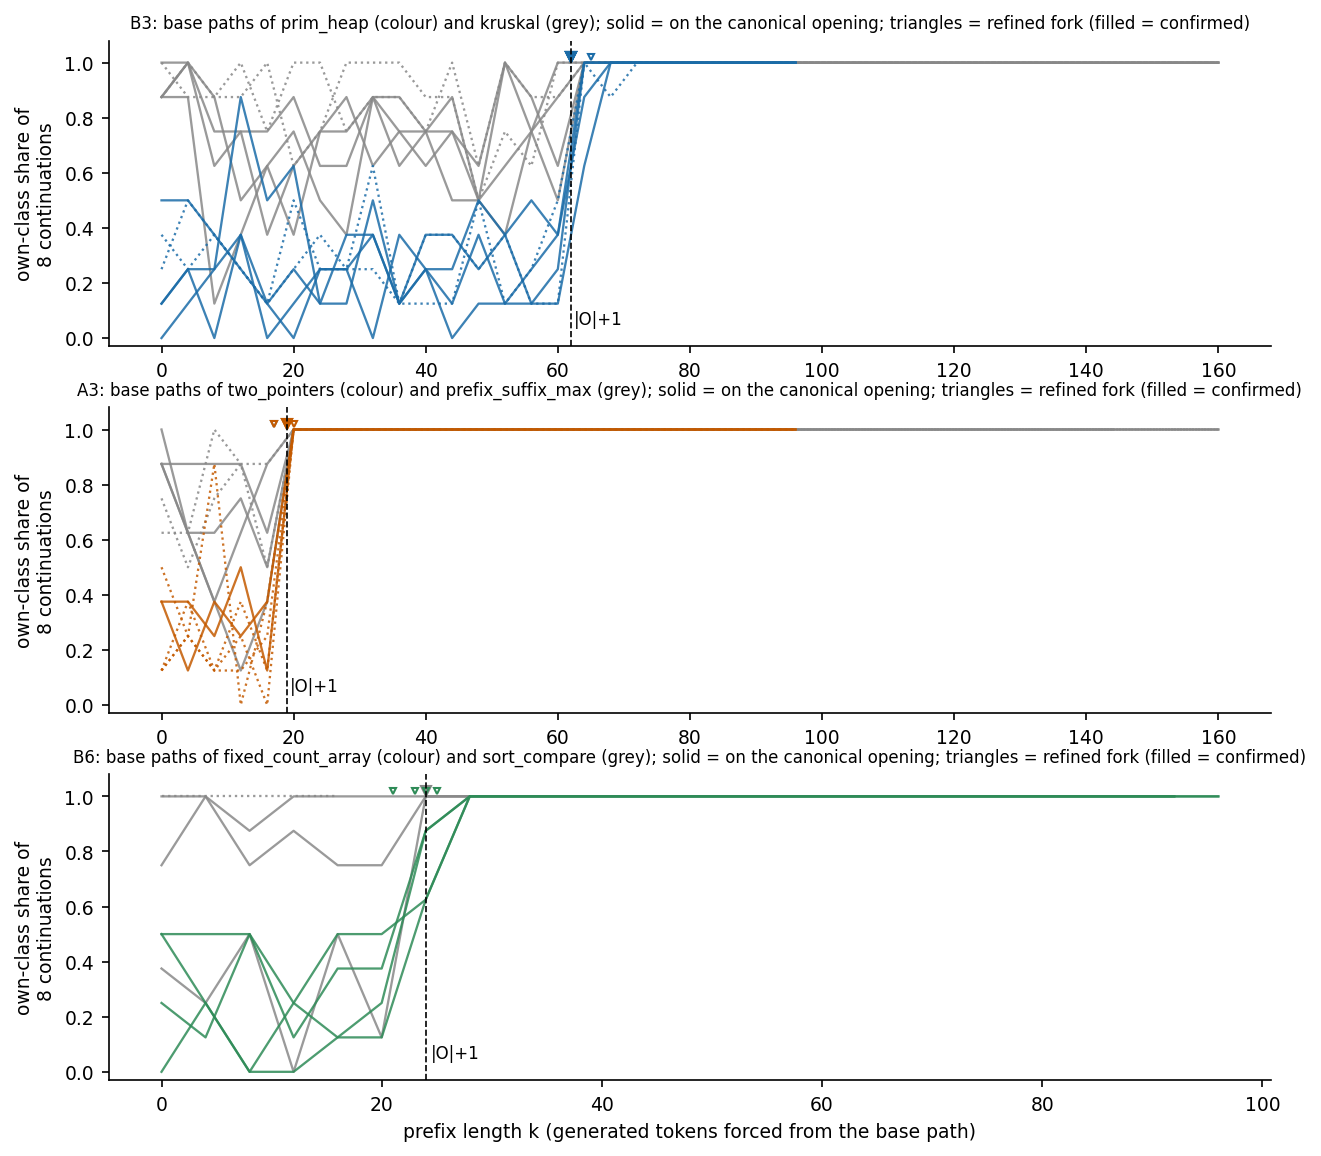

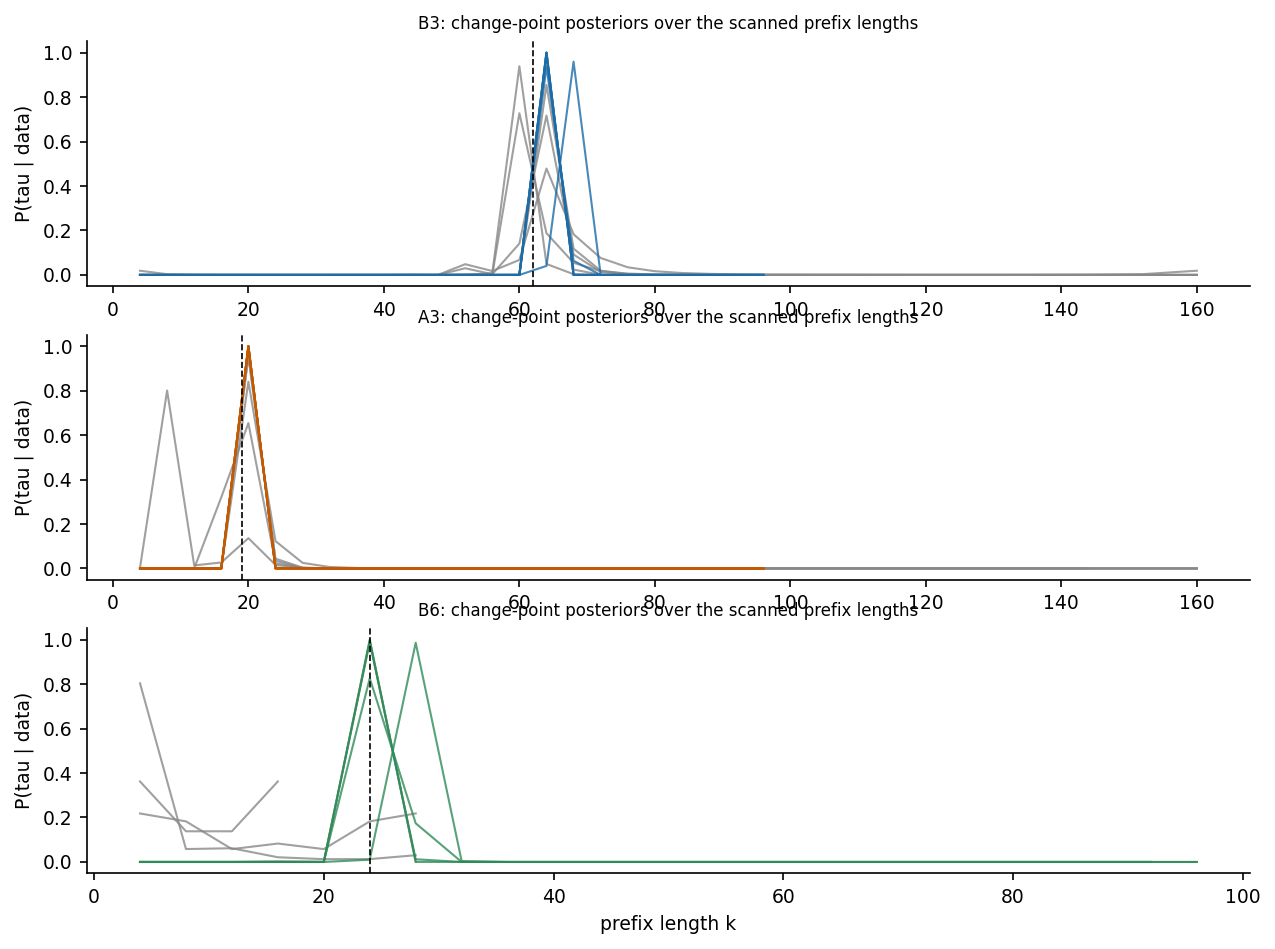

In [14]:
# ---- src/figures7.py: style, colours and save() ----
# matplotlib.use("Agg")                         # dropped: the notebook draws inline
plt.rcParams.update({"font.size": 9, "axes.spines.top": False, "axes.spines.right": False, "pdf.fonttype": 42,
                     "ps.fonttype": 42, "figure.dpi": 150})
COL = {"B3": "#1b6ca8", "A3": "#c45a00", "B6": "#2e8b57", "T1": "#7a4f9a", "T2": "#a33b3b", "T10": "#556b2f",
       "T03": "#8b6914"}
import warnings                                 # notebook: one A3 fork token is a CJK character the font lacks
warnings.filterwarnings("ignore", message="Glyph .* missing from font")


def save(fig, name: str) -> None:
    # was: fig.savefig(FIG_DIR / f"{name}.pdf", ...); fig.savefig(FIG_DIR / f"{name}.png", ...); plt.close(fig)
    plt.show()


def f1_outcome_curves() -> None:
    F = meta["forks"]                           # was: read_json(RESULTS_DIR / "forks.json")
    units = [u for u in ("B3", "A3", "B6") if u in F]
    nb = max(len(F[u]["base_paths"]) for u in units)
    fig, axes = plt.subplots(len(units), 1, figsize=(10, 3.0 * len(units)), squeeze=False)
    for i, u in enumerate(units):
        ax = axes[i, 0]
        L = F[u]["opening"]["len_O"]
        for b in F[u]["base_paths"]:
            ib = F[u]["per_base_path"][b["bid"]]
            ks = ib["ks"]
            col = COL[u] if b["cls"] == F[u]["A_min"] else "#888888"
            ls = "-" if b["on_O"] else ":"
            ax.plot(ks, ib["own_share"], ls, color=col, lw=1.1, alpha=0.85)
            if ib.get("f"):
                ax.plot([ib["f"]], [1.02], "v", color=col, ms=5 if ib.get("confirmed") else 3,
                        mfc=col if ib.get("confirmed") else "none")
            for c in ib["cps"]:
                if c.get("post"):
                    pass
        ax.axvline(L + 1, color="k", lw=0.8, ls="--")
        ax.text(L + 1.5, 0.05, "|O|+1", fontsize=8)
        ax.set_ylabel("own-class share of\n8 continuations")
        ax.set_title(f"{u}: base paths of {F[u]['A_min']} (colour) and {F[u]['D']} (grey); solid = on the canonical "
                     f"opening; triangles = refined fork (filled = confirmed)", fontsize=8)
        ax.set_ylim(-0.03, 1.08)
    axes[-1, 0].set_xlabel("prefix length k (generated tokens forced from the base path)")
    save(fig, "F1_outcome_curves")
    # change-point posteriors (second page)
    fig, axes = plt.subplots(len(units), 1, figsize=(10, 2.4 * len(units)), squeeze=False)
    for i, u in enumerate(units):
        ax = axes[i, 0]
        for b in F[u]["base_paths"]:
            ib = F[u]["per_base_path"][b["bid"]]
            arr = np.array(ib["series"])
            # from forks import single_cp       # defined in the forks.py cell above
            r = single_cp(arr)
            if r["post"]:
                col = COL[u] if b["cls"] == F[u]["A_min"] else "#888888"
                ax.plot(ib["ks"][1:], r["post"], color=col, lw=1, alpha=0.8)
        ax.axvline(F[u]["opening"]["len_O"] + 1, color="k", lw=0.8, ls="--")
        ax.set_ylabel("P(tau | data)")
        ax.set_title(f"{u}: change-point posteriors over the scanned prefix lengths", fontsize=8)
    axes[-1, 0].set_xlabel("prefix length k")
    save(fig, "F1b_changepoint_posteriors")


f1_outcome_curves()

## Stage `predict` (CPU part): the functions of `src/predictions7.py`

**The input: `predictions_raw.json`, the GPU output.** For each unit and opening cluster c it holds the 20 most likely fork tokens t, and for each token:
- its teacher-forced T = 1 probability under every template, `pi1_by_template`;
- the labels of the ~40 continuations sampled after it, `counts`, which give P̂(A | t).

**The functions (verbatim).**
- **`h_conditional`: D3, Test 1's statistic.**
  - Each fork token gets its class C(t) = argmax_A P̂(A | t).
  - H(A | C) is the entropy of the algorithm given that class, weighted by π₁ and by cluster coverage.
  - A value near 0 bits means the class of one token fixes the algorithm.
- **`margins`.** m = log P₁(default-class tokens) − log P₁(other tokens) at the fork. For a binary fork, the minority share at temperature T is 1 / (1 + e^{m/T}).
- **`topk_report`.** The minority-class mass outside the top-10 tokens.
- **`s4_predictions`.** The S4 arms run through the same prediction function.
  - It loses its twin and push parts: those logits are not in the demo data.

**Two notebook helpers stand in for the removed `cache/tf/` files.**
- **`fork_logits_from_pi1`.** It rebuilds a fork distribution from the stored π₁ of the 20 expanded tokens. Their logs are the logits up to a constant. All other tokens (residual mass ~1e-5) are pooled into one residual token at the unused id V − 1.
- **`load_s4_npz`.** It rebuilds the S4(b) logits from their compressed rows. Each row keeps its top-32 logits and every token the prediction function reads; everything else becomes one log-sum-exp residual. This is exact at T = 1.

In [15]:
# ---- src/predictions7.py (verbatim functions; the cache/tf loads are replaced where marked) ----
def norm(v: np.ndarray, fb: np.ndarray) -> np.ndarray:
    v = np.asarray(v, dtype=float)
    return v / v.sum() if v.sum() > 0 else np.asarray(fb, dtype=float)


def phat_tables(U: dict[str, Any], cl: dict[str, Any], q_rest: np.ndarray, u: str, cid: str,
                counts_override: dict[str, np.ndarray] | None = None) -> tuple[dict[int, np.ndarray], np.ndarray]:
    cnt = counts_override or {t: np.array(v, dtype=float) for t, v in cl["counts"].items()}
    ph = {int(t): norm(v, q_rest) for t, v in cnt.items()}
    res = norm(np.array(cl["resid_counts"], dtype=float), q_rest)
    return ph, res


def h_conditional(U: dict[str, Any], rng: np.random.Generator | None = None) -> dict[str, Any]:
    """H(A | C) over all clusters (weighted by cluster coverage), C(t) = argmax_A Phat(A | t); the residual bin is its
    own token. With rng: one bootstrap replicate (multinomial resampling of every token's continuations)."""
    C = U["cats"]
    q_rest = np.array(U["q_rest"])
    covs = {cid: cl["cov"] for cid, cl in U["clusters"].items()}
    wsum = sum(covs.values())
    joint: dict[str, np.ndarray] = {}
    per_tok = []
    undecided_mass = 0.0
    for cid, cl in U["clusters"].items():
        wc = covs[cid] / wsum
        pis = {int(t): v for t, v in cl["pi1_avg"].items()}
        items = [(t, np.array(cl["counts"][str(t)], dtype=float), pis[t]) for t in pis]
        items.append(("resid", np.array(cl["resid_counts"], dtype=float), max(0.0, 1 - sum(pis.values()))))
        for t, cnt, m in items:
            if cnt.sum() == 0:
                continue
            if rng is not None:
                cnt = rng.multinomial(int(cnt.sum()), cnt / cnt.sum()).astype(float)
            ph = cnt / cnt.sum()
            cls = C[int(np.argmax(ph))]
            joint.setdefault(cls, np.zeros(len(C)))
            joint[cls] += wc * m * ph
            if rng is None:
                per_tok.append({"cluster": cid, "tok": t, "pi1": m, "class": cls, "phat": ph.tolist(),
                                "H_bits": FK.entropy_bits(ph), "n": int(cnt.sum())})
            dshare = ph[C.index(U["D"])]
            if 0.2 <= dshare <= 0.8:
                undecided_mass += wc * m
    tot = sum(v.sum() for v in joint.values())
    H = sum((v.sum() / tot) * FK.entropy_bits(v / v.sum()) for v in joint.values() if v.sum() > 0)
    return {"H_bits": float(H), "class_mass": {c: float(v.sum() / tot) for c, v in joint.items()},
            "per_token": per_tok, "undecided_mass": float(undecided_mass)}


def margins(U: dict[str, Any], tfs: dict[str, dict[str, dict[str, np.ndarray]]] | None = None,
            z_override: dict[str, dict[str, np.ndarray]] | None = None) -> dict[str, Any]:
    """m_c = log P_1(D-class tokens) - log P_1(non-D tokens) at the fork, per template (D-class: argmax Phat = D;
    tokens outside the expanded set count by the residual bin's class)."""
    C = U["cats"]
    out = {}
    for cid, cl in U["clusters"].items():
        ph = {int(t): np.array(v, dtype=float) for t, v in cl["counts"].items()}
        dtoks = [t for t, v in ph.items() if v.sum() and C[int(np.argmax(v))] == U["D"]]
        res = np.array(cl["resid_counts"], dtype=float)
        res_is_d = res.sum() > 0 and C[int(np.argmax(res))] == U["D"]
        ms = {}
        keys = list(z_override[cid]) if z_override and cid in z_override else list(TEMPLATES)
        for w in keys:
            z = (z_override or {}).get(cid, {}).get(w) if z_override else None
            if z is None:
                z = (tfs or {}).get(cid, {}).get(w, {}).get("z_fork") if tfs else None
            if z is None:
                z = load_tf_cached(U["_unit"], cid)[w]["z_fork"]       # (cache/tf; never reached in this notebook)
            p = PR.dist(z, 1.0, 0)
            exp_mass = float(sum(p[int(t)] for t in ph))
            pd = float(sum(p[t] for t in dtoks)) + (max(0.0, 1 - exp_mass) if res_is_d else 0.0)
            pd = min(max(pd, 1e-12), 1 - 1e-12)
            ms[w] = math.log(pd) - math.log(1 - pd)
        out[cid] = {"by_template": ms, "mean": float(np.mean(list(ms.values()))), "n_D_tokens": len(dtoks)}
    return out


def topk_report(U: dict[str, Any]) -> dict[str, Any]:
    C = U["cats"]
    out = {}
    for cid, cl in U["clusters"].items():
        rows = []
        for t, v in cl["counts"].items():
            v = np.array(v, dtype=float)
            if v.sum() == 0 or C[int(np.argmax(v))] != U["A_min"]:
                continue
            for w in TEMPLATES:
                rk = cl["rank_by_template"][w][t]
                rows.append({"tok": int(t), "text": cl["tok_text"][t], "template": w, "rank": rk,
                             "pi1": cl["pi1_by_template"][w][t], "outside_top10": rk > 10})
        mass_out = {w: sum(r["pi1"] for r in rows if r["template"] == w and r["outside_top10"]) for w in TEMPLATES}
        out[cid] = {"minority_tokens": rows, "minority_mass_outside_top10": mass_out}
    return out


def s4_predictions(u: str, U: dict[str, Any], S4: dict[str, Any]) -> dict[str, Any]:
    """Pushed / exchanged teacher-forced numbers through the same prediction function (T 1, full sampler)."""
    cid = S4["cluster"]
    cl = U["clusters"][cid]
    C = U["cats"]
    q_rest = np.array(U["q_rest"])
    ph, res = phat_tables(U, cl, q_rest, u, cid)
    def pred_of(tf_w: dict[str, dict[str, np.ndarray]]) -> dict[str, Any]:
        sh, on = [], []
        for w, tf in tf_w.items():
            r = PR.cell_prediction([{"Z_open": tf["Z_open"], "O": cl["O"], "z_fork": tf["z_fork"], "phat": ph,
                                     "resid": res}], q_rest, 1.0, 0)
            sh.append(float(r["P"][C.index(U["A_min"])]))
            on.append(r["on_opening"])
        Uc = {**U, "clusters": {cid: cl}}
        m = margins(Uc, z_override={cid: {w: tf["z_fork"] for w, tf in tf_w.items()}})[cid]["mean"]
        return {"s_pred": float(np.mean(sh)), "on_opening": float(np.mean(on)), "margin": m}
    # base = pred_of({w: load_tf_cached(u, cid)[w] for w in TEMPLATES})      # twin logits: not in the demo data
    out = {"exchange": {}}                                                    # was: {"twin": base, "push": {}, ...}
    # for d in DIRECTIONS: ... np.load(TF_DIR / f"{u}_push{d}_{w}.npz") ...  # S4(a) push logits: not in the demo data
    for name in ("forced", "forced_pad", "exchange", "MR"):
        z = load_s4_npz(u, name)                                              # was: np.load(TF_DIR / f"{u}_{name}.npz")
        r = pred_of({"F": {"Z_open": z["Zo"].astype(np.float64), "z_fork": z["zf"].astype(np.float64)}})
        out["exchange"][name] = r
    pad = out["exchange"]["forced_pad"]
    for name in ("exchange", "MR", "forced"):
        out["exchange"][name]["d_margin_vs_pad"] = out["exchange"][name]["margin"] - pad["margin"]
    return out


# ---- notebook helpers: stand-ins for the full-vocabulary logits of cache/tf/ (removed after the round) ----
V_VOCAB = 151936   # Qwen3-8B vocabulary rows; ids 151669-151935 are unused padding


def fork_logits_from_pi1(cl: dict[str, Any], w: str) -> np.ndarray:
    """Fork logits of cluster cl under template w, rebuilt from the stored teacher-forced T = 1 probabilities of the
    expanded fork tokens (log pi_1 = logit - logsumexp); every other token is pooled into one residual token at the
    unused id V - 1 with log(1 - sum pi_1); all remaining ids get -inf."""
    z = np.full(V_VOCAB, -np.inf)
    pis = cl["pi1_by_template"][w]
    for t, p in pis.items():
        z[int(t)] = math.log(p)
    z[V_VOCAB - 1] = math.log(max(1.0 - sum(pis.values()), 1e-300))
    return z


def load_s4_npz(u: str, name: str) -> dict[str, np.ndarray]:
    """The teacher-forced logits of S4(b) arm `name` (opening rows Zo and fork row zf), rebuilt from the compressed
    rows in mini_demo_data.json: the kept logits at their token ids, the log-sum-exp of every other logit at the
    unused id V - 1 (exact softmax at T = 1 for every kept token), -inf elsewhere."""
    S = meta["s4_logits"][u]
    V = S["V"]

    def row(c: dict[str, Any]) -> np.ndarray:
        z = np.full(V, -np.inf)
        z[c["ids"]] = c["vals"]
        z[V - 1] = c["lse_rest"]
        return z
    arm = S["arms"][name]
    return {"Zo": np.stack([row(c) for c in arm["Zo"]]), "zf": row(arm["zf"])}

### Test 1's statistic, the fork margins and the top-k report

The loop follows `build_commit2()` in `src/predictions7.py`. For each unit it computes:
- H(A | C), with `N_BOOT` multinomial bootstrap replicates (seed 20261022, as in the full run);
- the margins, from the rebuilt fork logits;
- the top-k report.

**Expected.**
- H stays far below the 0.3-bit threshold: **0.050 / 0.153 / 0.189 bits** (B3 / A3 / B6).
- At `N_BOOT` = 1000 the bootstrap CI equals the committed one.
- The margins match the committed values.
- The minority mass outside the top 10 is < 3e-4 on every template, which is why top-k 10 cannot change the algorithm.

The second table lists B3's leading fork tokens. ` Kr` and ` Prim` carry ~99% of the mass, and each has a pure class.

In [16]:
R = meta["units"]                        # was: read_json(PRED_DIR / "predictions_raw.json")
committed = meta["committed"]["units"]   # COMMIT #2's predictions_view.json, for comparison
t0 = time.time()
pred_demo = {}
for u, U in R.items():
    U = {**U, "_unit": u}
    # ---- from build_commit2() (src/predictions7.py) ----
    hc = h_conditional(U)
    rng = np.random.default_rng(20261022)
    boots = [h_conditional(U, rng)["H_bits"] for _ in range(N_BOOT)]          # was: range(1000)
    rec = {"test1": {"H_bits": hc["H_bits"], "H_boot_ci95": [float(np.percentile(boots, 2.5)),
                                                             float(np.percentile(boots, 97.5))],
                     "H_upper95": float(np.percentile(boots, 95)), "class_mass": hc["class_mass"],
                     "undecided_mass": hc["undecided_mass"], "per_token": hc["per_token"]}}
    # was: rec["margins"] = margins(U)  -- which reads the fork logits from cache/tf
    rec["margins"] = margins(U, z_override={cid: {w: fork_logits_from_pi1(cl, w) for w in TEMPLATES}
                                            for cid, cl in U["clusters"].items()})
    rec["topk_report"] = topk_report(U)
    pred_demo[u] = rec
print(f"D3 + margins + top-k report in {time.time() - t0:.1f}s (N_BOOT = {N_BOOT})")

t1_rows = []
for u, rec in pred_demo.items():
    c, t1d = committed[u], rec["test1"]
    t1_rows.append({"unit": u, "D vs A_min": f"{R[u]['D']} vs {R[u]['A_min']}",
                    "H bits": t1d["H_bits"], "committed H": c["test1"]["H_bits"],
                    "bootstrap 95% CI": np.round(t1d["H_boot_ci95"], 3).tolist(),
                    "committed CI": np.round(c["test1"]["H_boot_ci95"], 3).tolist(),
                    "margin c0 (nats)": rec["margins"]["c0"]["mean"], "committed margin c0": c["margins"]["c0"]["mean"],
                    "minority mass outside top-10 (max)": max(m for cr in rec["topk_report"].values()
                                                              for m in cr["minority_mass_outside_top10"].values())})
display(pd.DataFrame(t1_rows).round(4))

cl = R["B3"]["clusters"]["c0"]
tok_rows = [{"fork token": repr(cl["tok_text"][str(p["tok"])]), "pi_1 (template mean)": p["pi1"],
             "class C(t)": p["class"], "Phat(kruskal | t)": p["phat"][0], "Phat(prim_heap | t)": p["phat"][1],
             "continuations": p["n"]}
            for p in pred_demo["B3"]["test1"]["per_token"] if p["cluster"] == "c0" and p["tok"] != "resid"][:8]
print("\nB3, opening cluster c0 -- the fork right after", repr(cl["O_text"][-40:]))
display(pd.DataFrame(tok_rows).round(4))

D3 + margins + top-k report in 1.1s (N_BOOT = 1000)


,unit,D vs A_min,H bits,committed H,bootstrap 95% CI,committed CI,margin c0 (nats),committed margin c0,minority mass outside top-10 (max)
0,B3,kruskal vs prim_heap,0.0503,0.0503,"[0.014, 0.096]","[0.014, 0.096]",0.9946,0.9946,0.0002
1,A3,prefix_suffix_max vs two_pointers,0.1527,0.1527,"[0.091, 0.203]","[0.091, 0.203]",1.5500,1.5500,0.0000
2,B6,sort_compare vs fixed_count_array,0.1894,0.1894,"[0.123, 0.239]","[0.123, 0.239]",1.4451,1.4451,0.0000



B3, opening cluster c0 -- the fork right after ')\n        graph[v].append((u, w))\n\n    #'


,fork token,pi_1 (template mean),class C(t),Phat(kruskal | t),Phat(prim_heap | t),continuations
0,' Kr',0.7174,kruskal,1.000,0.000,40
1,' Prim',0.2739,prim_heap,0.025,0.975,40
2,' Pr',0.0032,prim_heap,0.050,0.950,40
3,' Initialize',0.0028,kruskal,0.525,0.450,40
4,' Check',0.0010,kruskal,1.000,0.000,40
5,' Union',0.0009,kruskal,1.000,0.000,40
6,' Use',0.0003,prim_heap,0.250,0.750,40
7,' Minimum',0.0002,kruskal,0.675,0.325,40


### F2: the fork-token distribution (`src/figures7.py`)

Each bar is one candidate fork token. Its height is the teacher-forced probability π₁(t) at T = 1, averaged over templates and drawn on a log scale. Its colour is P̂(A_min | t): red tokens lead to the minority algorithm and blue tokens to the default.

The dashed line marks the top-k 10 cut. All the minority-class mass sits well inside it.

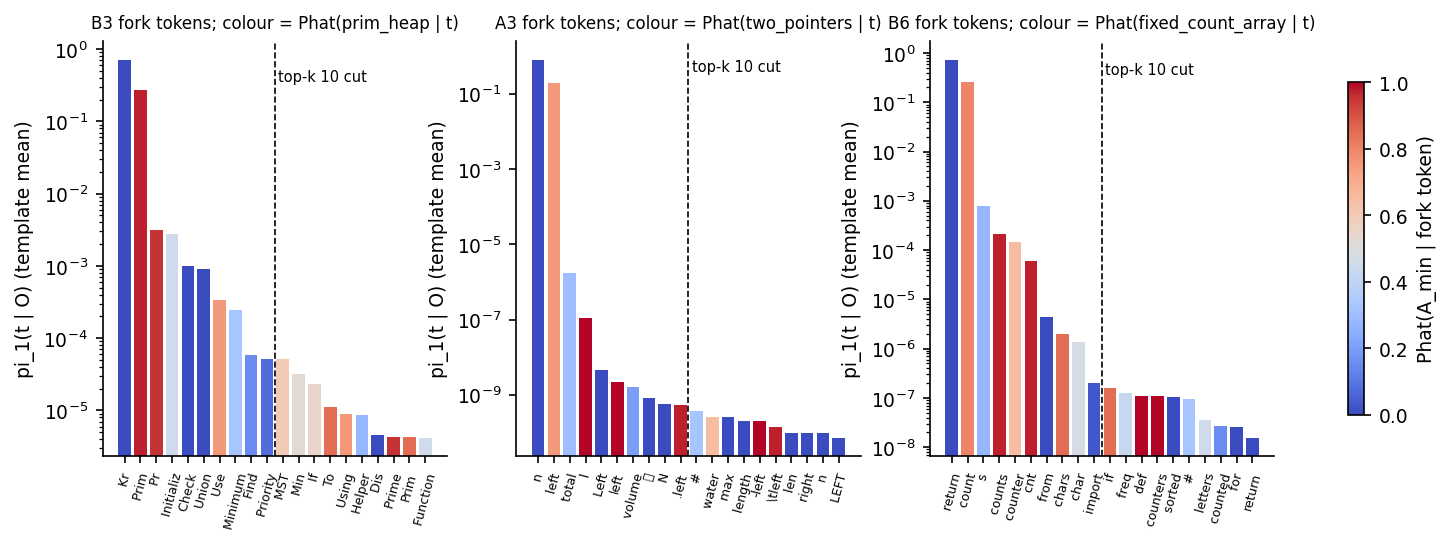

In [17]:
# ---- src/figures7.py: f2_fork_tokens (verbatim apart from the data source) ----
def f2_fork_tokens() -> None:
    R = meta["units"]                           # was: read_json(PRED_DIR / "predictions_raw.json")
    units = [u for u in ("B3", "A3", "B6") if u in R]
    fig, axes = plt.subplots(1, len(units), figsize=(4.2 * len(units), 3.6), squeeze=False)
    for i, u in enumerate(units):
        ax = axes[0, i]
        cid = sorted(R[u]["clusters"])[0]
        cl = R[u]["clusters"][cid]
        C = R[u]["cats"]
        A = R[u]["A_min"]
        toks = sorted(cl["toks"], key=lambda t: -cl["pi1_avg"][str(t)])[:25]
        pis = [cl["pi1_avg"][str(t)] for t in toks]
        ph = []
        for t in toks:
            v = np.array(cl["counts"][str(t)], float)
            ph.append(v[C.index(A)] / v.sum() if v.sum() else np.nan)
        cmap = plt.get_cmap("coolwarm")
        ax.bar(range(len(toks)), pis, color=[cmap(p) if np.isfinite(p) else "#cccccc" for p in ph])
        ax.set_yscale("log")
        ax.axvline(9.5, color="k", ls="--", lw=0.8)
        ax.text(9.7, max(pis) * 0.5, "top-k 10 cut", fontsize=7)
        ax.set_xticks(range(len(toks)))
        ax.set_xticklabels([repr(cl["tok_text"][str(t)])[1:-1][:10] for t in toks], rotation=75, fontsize=6)
        ax.set_ylabel("pi_1(t | O) (template mean)")
        ax.set_title(f"{u} fork tokens; colour = Phat({A} | t)", fontsize=8)
    sm = plt.cm.ScalarMappable(cmap="coolwarm", norm=plt.Normalize(0, 1))
    fig.colorbar(sm, ax=axes.ravel().tolist(), shrink=0.8, label="Phat(A_min | fork token)")
    save(fig, "F2_fork_token_probabilities")


f2_fork_tokens()

### S4(b): exchanging the task-specification states moves the fork

S4(b) compares four arms on the main opening cluster:

| arm | what it is |
|---|---|
| **forced** | the prompt *"Implement <minority algorithm> for this task."* |
| **forced_pad** | its padding twin: the same prompt with the instruction replaced by `" ."` |
| **exchange** | the padding twin, with the forced prompt's residual states copied in at every task-spec position, in all 36 blocks |
| **MR** | a matched-norm random exchange at the same sites (the control) |

For each arm the full run saved the teacher-forced logits along the opening and at the fork. The A3 and B6 arms are in the demo file; B3's were removed with the cache.

`s4_predictions` runs them through the **committed prediction function**: the opening walk `w(c)`, the fork mix `F(c, A)` and the margin.

**Expected (COMMIT #2).**
- The exchange moves the fork margin by −5.5 nats on A3 and −22.1 nats on B6. MR moves it by only −2.0 and +0.3.
- In the generated programs (30 slots per arm), the exchange gave the minority algorithm on **30 of 30** slots of every unit, against 4/30 and 0/30 for the padding twin.

In [18]:
S4 = {u: {"cluster": meta["s4_logits"][u]["cluster"]} for u in meta["s4_logits"]}   # was: predictions/s4_raw.json
t0 = time.time()
s4_demo = {u: s4_predictions(u, {**R[u], "_unit": u}, S4[u]) for u in S4}
print(f"S4(b) teacher-forced predictions for {list(S4)} in {time.time() - t0:.1f}s\n")

ARM = {"forced": "FORCED", "forced_pad": "FORCEDPAD", "exchange": "EXCH", "MR": "MR"}   # arm names in results/s4b.json
s4_rows = []
for u, s in s4_demo.items():
    for name in ("forced_pad", "MR", "exchange", "forced"):
        r, c = s["exchange"][name], committed[u]["s4"]["exchange"][name]
        s4_rows.append({"unit": u, "arm": name, "predicted A_min share": r["s_pred"],
                        "committed prediction": c["s_pred"], "P(stay on opening)": r["on_opening"],
                        "fork margin (nats)": r["margin"], "committed margin": c["margin"],
                        "margin shift vs pad": r.get("d_margin_vs_pad", 0.0),
                        "observed A_min share (full run, 30 slots)":
                            meta["full_run"]["s4b"][u]["arms"][ARM[name]]["attempted_a_min"]})
display(pd.DataFrame(s4_rows).round(4))

S4(b) teacher-forced predictions for ['A3', 'B6'] in 0.1s



,unit,arm,predicted A_min share,committed prediction,P(stay on opening),fork margin (nats),committed margin,margin shift vs pad,"observed A_min share (full run, 30 slots)"
0,A3,forced_pad,0.1939,0.1939,0.4369,1.5000,1.5000,0.0000,0.1333
1,A3,MR,0.3661,0.3661,0.5595,-0.5000,-0.5000,-2.0000,0.1333
2,A3,exchange,0.4048,0.4048,0.3344,-4.0000,-4.0000,-5.5000,1.0000
3,A3,forced,0.2639,0.2639,0.0504,-7.2500,-7.2500,-8.7500,1.0000
4,B6,forced_pad,0.0011,0.0011,0.2687,5.2388,5.2388,0.0000,0.0000
5,B6,MR,0.0005,0.0005,0.1479,5.4943,5.4943,0.2556,0.0000
6,B6,exchange,0.7806,0.7806,0.9757,-16.8768,-16.8768,-22.1155,1.0000
7,B6,forced,0.4044,0.4044,0.5057,-20.0013,-20.0013,-25.2401,1.0000


## Stage `commit2`, in miniature: hash the predictions before scoring them

The full run sha256-committed every prediction before the first sweep sample was drawn (COMMIT #2). The commit also holds the hashes of the scoring code.

The demo mirrors this. It assembles its prediction view and commits it to a fresh chain in `DEMO_DIR` with the artifact's `commit()`. The view holds:
- COMMIT #2's cell predictions and per-slot replays, loaded;
- this notebook's recomputed Test 1 statistics and margins.

`verify()` re-checks the chain just before Test 2 is scored.

In [19]:
pv = json.loads(json.dumps(meta["committed"]))     # a copy of COMMIT #2's predictions_view.json
for u, rec in pred_demo.items():
    pv["units"][u]["test1"] = rec["test1"]          # recomputed above (D3)
    pv["units"][u]["margins"] = rec["margins"]      # recomputed above from the rebuilt fork logits
info = CM.commit("commit2_demo", {"predictions": pv, "note": "demo: committed before Test 2 is scored"})
print("commit:", info["name"], "| file sha256", info["sha256"][:16], "... | chain", info["chain"][:16], "...")
print("verify:", CM.verify())
print("\ncommitted cell predictions, attempted minority share (top-p 1):")
display(pd.DataFrame({u: {f"T {T}": pv["units"][u]["cells"][f"T{T}_p1"]["a_min"] for T in TEMPS}
                      for u in MIXED}).T.round(3))

commit: commit2_demo | file sha256 bc495536cc0b08d2 ... | chain 4bc67a7682c1f1f8 ...
verify: {'ok': True, 'n': 1, 'bad': []}

committed cell predictions, attempted minority share (top-p 1):


,T 0.3,T 0.7,T 1.0,T 1.3
B3,0.068,0.193,0.237,0.247
A3,0.166,0.285,0.311,0.319
B6,0.161,0.182,0.200,0.212


## Stage `generate`: the same-seed sweep programs (the demo dataset)

**The full sweep.**
- It generated 3 units × 4 temperatures × 2 samplers × 50 slots = 1,200 programs.
- A slot is a template (W1–W5) times a slot index (20–29). It owns one CRN stream, so the same uniforms drive it in all 8 cells.
- The frozen labellers labelled each program from hidden tests, a runtime tracer and the AST.

**The demo dataset.** The 100 B3 programs of slots 20–24 under top-p 1: 25 slots × 4 temperatures.

**`rows_with_labels()`.** The artifact's version joins `samples_raw.jsonl`, `labels.jsonl` and the judge labels. Here it reads the same fields from the examples, keeping the slots and samplers chosen in the config cell.

Below, one slot is shown at all four temperatures: same prompt, same uniform stream. Only T differs, and with it the comment word after `    # ` and the algorithm.

In [20]:
# ---- src/analysis_T.py: rows_with_labels() -- the same rows, data source replaced ----
def rows_with_labels() -> list[dict[str, Any]]:
    """Program rows with their frozen labels; a 'disputed' label (labeller disagreement) is replaced by the blind
    judges' majority label when one exists (data/judge_labels.jsonl), else it stays 'disputed' (counted, not A)."""
    # was: joined data/samples_raw.jsonl, data/labels.jsonl and data/judge_labels.jsonl; every demo example carries
    #      that join already (metadata_token_ids, metadata_label, metadata_passed, metadata_code)
    out = []
    for e in examples:
        if e["metadata_slot"] not in SWEEP_SLOTS or e["metadata_cell"].split("_")[1] not in SAMPLERS:
            continue                                     # notebook: only the slots / samplers of the config cell
        out.append({"sid": e["metadata_sid"], "unit": e["metadata_unit"], "arm": e["metadata_arm"],
                    "cell": e["metadata_cell"], "template": e["metadata_template"], "slot": e["metadata_slot"],
                    "T": e["metadata_temperature"], "top_k": e["metadata_top_k"],
                    "ukey": e["metadata_crn_key"].split("|"), "token_ids": e["metadata_token_ids"],
                    "n_new_tokens": e["metadata_n_new_tokens"], "finish_reason": e["metadata_finish_reason"],
                    "text": e["metadata_generation"], "prompt": e["input"], "label": e["metadata_label"],
                    "passed": e["metadata_passed"], "code": e["metadata_code"]})
    return out


rows = rows_with_labels()
print(f"{len(rows)} sweep programs: unit(s) {sorted({r['unit'] for r in rows})}, slots {SWEEP_SLOTS} x "
      f"{len(TEMPLATES)} templates x {len(TEMPS)} temperatures, sampler(s) {list(SAMPLERS)}")
display(pd.crosstab([pd.Series([r["unit"] for r in rows], name="unit"),
                     pd.Series([r["label"] for r in rows], name="label")],
                    pd.Series([r["cell"] for r in rows], name="cell")))

# one slot -- one prompt, one uniform stream -- under the four temperatures
by_slot = defaultdict(dict)
for r in rows:
    if r["unit"] == "B3" and r["top_k"] == 0:            # B3 under top-p 1 (also when the full sweep is loaded)
        by_slot[(r["template"], r["slot"])][r["T"]] = r
flip = next((k for k, v in by_slot.items() if len({x["label"] for x in v.values()}) > 1), next(iter(by_slot)))
print(f"\nslot {flip[0]}|{flip[1]} (CRN key iter7T|B3|{flip[0]}|{flip[1]}); its prompt:\n")
print(by_slot[flip][TEMPS[0]]["prompt"])
for T in TEMPS:
    r = by_slot[flip][T]
    print(f"\n----- T {T}: {r['label']} ({'passes' if r['passed'] else 'fails'} the hidden tests, "
          f"{r['n_new_tokens']} tokens); first 12 lines:")
    print("\n".join(r["text"].splitlines()[:12]))

100 sweep programs: unit(s) ['B3'], slots (20, 21, 22, 23, 24) x 5 templates x 4 temperatures, sampler(s) ['p1']


cell            T0.3_p1  T0.7_p1  T1.0_p1  T1.3_p1
unit label                                        
B3   kruskal         23       18       14       12
     prim_heap        2        7       11       13


slot W1|21 (CRN key iter7T|B3|W1|21); its prompt:

Do not use house for this task. . . . .

Task: write a Python function solve(n, roads) that returns the smallest total cost of a choice of roads that links all cities. There are n cities numbered 0 to n - 1, where 1 <= n <= 500. The argument roads is a list of at most 10000 triples [u, v, w], each meaning that a two-way road between cities u and v (u != v) can be built for cost w, where 0 <= w <= 100000; several roads may join the same two cities. Choose roads so that every city can reach every other city through chosen roads, at the smallest possible total cost, and return that total as an int. If the cities cannot all be linked, return -1. For example, for n = 3 and roads = [[0, 1, 5], [0, 2, 6], [1, 2, 1]] the answer is 6.

Use only the Python standard library. Return only one ```python code block containing the function solve and any helpers, with no example usage and no explanation.

[slot 21, cell T0.3_p1]

----- T 0.3: kruskal 

## The same seed at four temperatures: replaying each program's fork-token draw

For every demo program that stayed on an opening cluster c, this cell takes:
- its own CRN uniform at the fork position, `u = u_stream('iter7T', unit, template, slot)[|O_c|]`;
- the fork distribution of its template and cluster.

It applies the sampler transform (`replay.pick`) at the program's temperature. The class of the picked token, C(t) = argmax P̂(A | t), is the replay's prediction for that program.

This is the fork step of the committed per-slot replay (`replay_slots` in `src/predictions7.py`), with two differences:
- the original also walks the opening with the full-vocabulary logits, which are not in the demo data; this replay starts at the opening the program actually took;
- it uses the rebuilt fork distribution.

COMMIT #2's own replay, which walks the whole opening, is printed for comparison.

**Expected.**
- The replayed fork token equals the generated one on nearly every program.
- Its class names the program's algorithm. The full run's committed replay did this on 90–98% of on-opening slots.
- In the grid, one uniform per row lands on ` Kr` at low T and on ` Prim` at higher T.

In [21]:
# ---- the fork step of replay_slots() (src/predictions7.py), on the demo programs ----
t0 = time.time()
zf_cache, rep = {}, []
for r in rows:
    u = r["unit"]
    U = R[u]
    C = U["cats"]
    q_rest = np.array(U["q_rest"])
    cid = FK.cluster_of(r["token_ids"], F[u]["opening"]["clusters"])     # the opening the program actually took
    sname = next(s for s, k in SAMPLERS.items() if k == r["top_k"])
    rec = {"unit": u, "sampler": sname, "slot": f"{r['template']}|{r['slot']}", "T": r["T"], "label": r["label"],
           "cluster": cid}
    if cid is not None:
        cl = U["clusters"][cid]
        i = len(cl["O"])                                                   # the fork is generated token |O_c|
        uu = u_stream("iter7T", u, r["template"], r["slot"])               # the slot's own CRN stream
        if (u, cid, r["template"]) not in zf_cache:
            zf_cache[(u, cid, r["template"])] = fork_logits_from_pi1(cl, r["template"])
        t = replay.pick(zf_cache[(u, cid, r["template"])], float(uu[i]), r["T"], SAMPLERS[sname])
        cnt = cl["counts"].get(str(t))
        v = np.array(cnt if cnt is not None else cl["resid_counts"], dtype=float)
        pred = C[int(np.argmax(v))] if v.sum() else C[int(np.argmax(q_rest))]
        rec.update({"u at fork": float(uu[i]),
                    "generated fork token": cl["tok_text"].get(str(r["token_ids"][i]), str(r["token_ids"][i])),
                    "replayed fork token": cl["tok_text"].get(str(t), "rest"), "token match": t == r["token_ids"][i],
                    "replay predicts": pred})
    cr = pv["units"][u]["replay"].get(f"{r['template']}|{r['slot']}|{r['cell']}")   # COMMIT #2's per-slot replay
    rec["committed replay predicts"] = cr["pred"] if cr else None
    rep.append(rec)
rep_df = pd.DataFrame(rep)
on = rep_df[rep_df["cluster"].notna()]
cm = rep_df[rep_df["committed replay predicts"].notna() &
            ~rep_df["committed replay predicts"].astype(str).str.startswith("rest:")]
print(f"fork-token replay of {len(rep_df)} programs in {time.time() - t0:.1f}s; {len(on)} stayed on an opening cluster")
print(f"  replayed fork token == generated fork token: {int(on['token match'].sum())}/{len(on)}")
print(f"  the replayed token's class == the program's algorithm: {int((on['replay predicts'] == on['label']).sum())}"
      f"/{len(on)}")
print(f"  COMMIT #2's replay (whole opening walked), on-opening predictions correct: "
      f"{int((cm['committed replay predicts'] == cm['label']).sum())}/{len(cm)}\n")


def _cell(x: pd.Series) -> str:
    if x["cluster"] is None or (isinstance(x["cluster"], float) and math.isnan(x["cluster"])):
        return f"(left the opening) {x['label']}"
    miss = "" if x["replay predicts"] == x["label"] else f"  [replay: {x['replay predicts']}]"
    return f"{x['replayed fork token']!r} -> {x['label']}{miss}"


g = rep_df[(rep_df["unit"] == "B3") & (rep_df["sampler"] == "p1")]          # the grid shows B3 under top-p 1
grid = g.assign(fork=g.apply(_cell, axis=1)).pivot(index="slot", columns="T", values="fork")
grid.insert(0, "u at fork", g.groupby("slot")["u at fork"].first().round(3))
print("B3, top-p 1 -- each row = one seed (slot); each column = one temperature; "
      "entry = replayed fork token -> generated algorithm")
display(grid)

fork-token replay of 100 programs in 0.1s; 85 stayed on an opening cluster
  replayed fork token == generated fork token: 82/85
  the replayed token's class == the program's algorithm: 82/85
  COMMIT #2's replay (whole opening walked), on-opening predictions correct: 82/84

B3, top-p 1 -- each row = one seed (slot); each column = one temperature; entry = replayed fork token -> generated algorithm


T,u at fork,0.3,0.7,1.0,1.3
slot,,,,,
W1|20,0.372,' Kr' -> kruskal,' Kr' -> kruskal,' Kr' -> kruskal,' Kr' -> kruskal
W1|21,0.832,' Kr' -> kruskal,' Kr' -> kruskal,' Prim' -> prim_heap,(left the opening) prim_heap
W1|22,0.164,' Kr' -> kruskal,' Kr' -> kruskal,' Kr' -> kruskal,' Kr' -> kruskal
W1|23,0.867,' Kr' -> kruskal,' Prim' -> prim_heap,' Prim' -> prim_heap,' Prim' -> prim_heap
W1|24,0.829,' Kr' -> kruskal,' Kr' -> kruskal,' Prim' -> prim_heap,' Prim' -> prim_heap
W2|20,0.926,' Prim' -> kruskal [replay: prim_heap],' Prim' -> prim_heap,' Prim' -> prim_heap,(left the opening) prim_heap
W2|21,0.207,' Kr' -> kruskal,' Kr' -> kruskal,' Kr' -> kruskal,' Kr' -> kruskal
W2|22,0.137,' Kr' -> kruskal,' Kr' -> kruskal,' Kr' -> kruskal,' Kr' -> kruskal
W2|23,0.609,' Kr' -> kruskal,' Kr' -> kruskal,' Kr' -> kruskal,' Prim' -> kruskal [replay: prim_heap]


### Why one seed changes its algorithm: the fork CDF in token-id order

Each stacked bar is B3's fork distribution under one template and temperature, laid out in **token-id order** as the sampler sees it. Blue bands are default-class tokens (` Kr` → Kruskal), orange bands are minority-class tokens (` Prim` → Prim), and grey bands are other or residual tokens.

Each triangle is one demo program on opening cluster c0, drawn at the height of its own uniform `u`. Its colour is the algorithm it actually wrote.

A slot keeps its `u` at every temperature. Lowering T stretches the ` Kr` band over almost the whole axis, so a `u` that falls in the ` Prim` band at T 1.0 lands in ` Kr` at T 0.3. This is the minority drop of Test 2, one seed at a time.

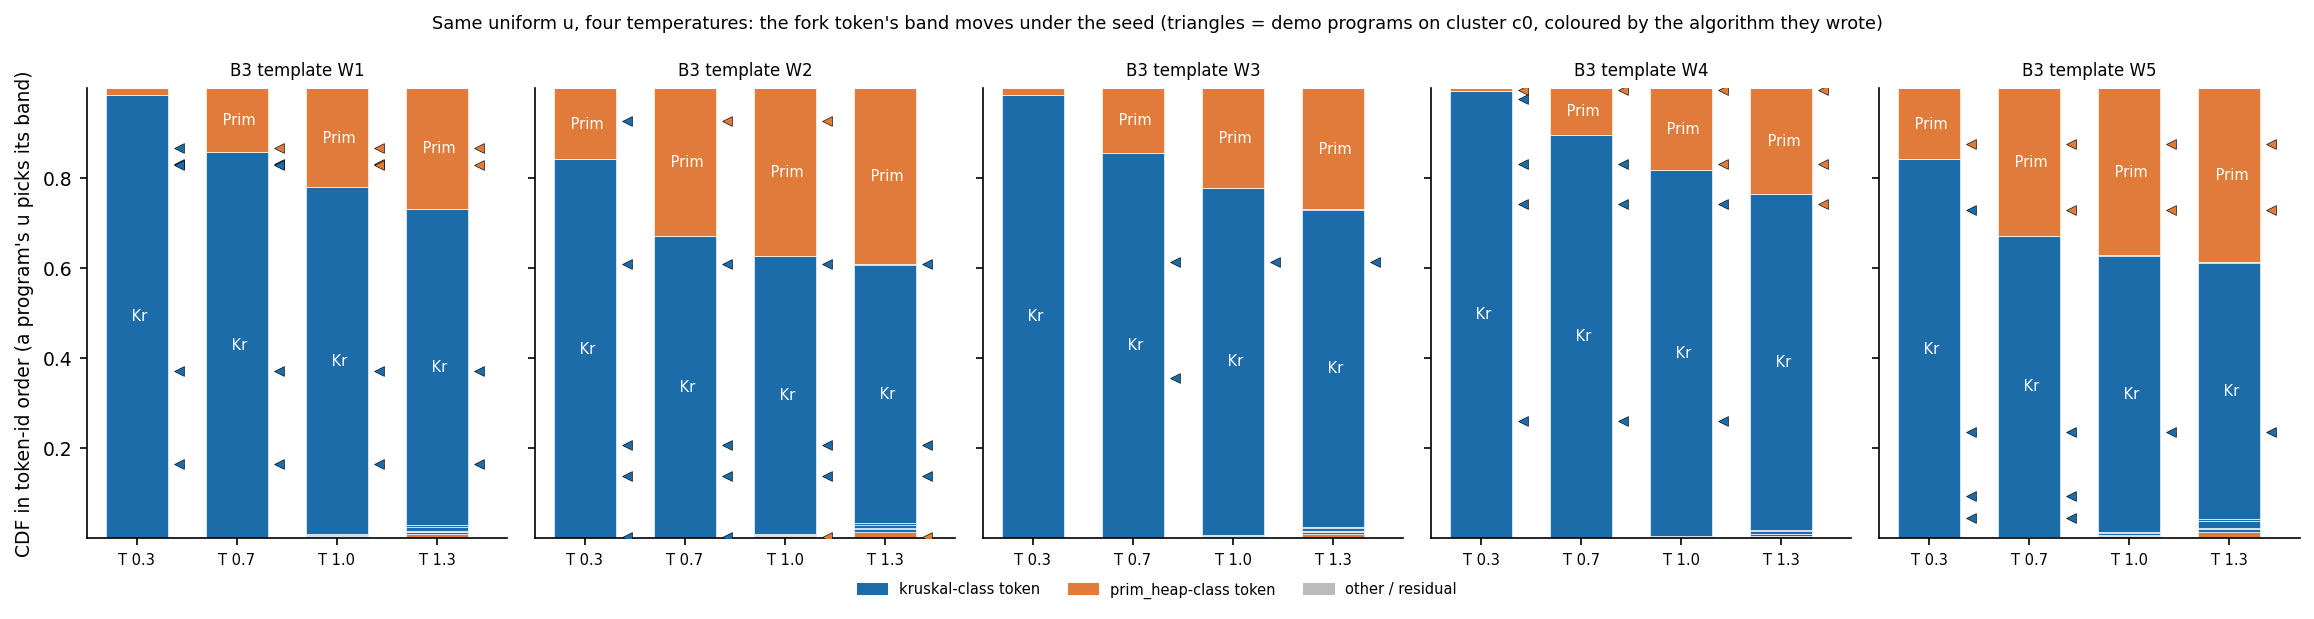

In [22]:
# ---- notebook figure: B3's fork step of the sampler, per template and temperature ----
U = R["B3"]
cl = U["clusters"]["c0"]
C = U["cats"]
CLS_COL = {U["D"]: COL["B3"], U["A_min"]: "#e07b39"}
fig, axes = plt.subplots(1, len(TEMPLATES), figsize=(3.1 * len(TEMPLATES), 3.9), sharey=True)
for ax, w in zip(axes, TEMPLATES):
    z = fork_logits_from_pi1(cl, w)
    ids = np.flatnonzero(np.isfinite(z))                       # the expanded tokens + the residual, in token-id order
    for j, T in enumerate(TEMPS):
        p = replay.probs(z, T, 0)[ids]
        lo = np.concatenate([[0.0], np.cumsum(p)[:-1]])
        for t, a, h in zip(ids, lo, p):
            cnt = cl["counts"].get(str(t))
            v = np.array(cnt if cnt is not None else cl["resid_counts"], dtype=float)
            ax.bar(j, h, bottom=a, width=0.62, color=CLS_COL.get(C[int(np.argmax(v))], "#bbbbbb"),
                   edgecolor="white", lw=0.3)
            if h > 0.07:
                ax.text(j, a + h / 2, repr(cl["tok_text"].get(str(t), "rest"))[1:-1], ha="center", va="center",
                        fontsize=7, color="white")
    for x in rep:
        if x["unit"] == "B3" and x["sampler"] == "p1" and x["cluster"] == "c0" and x["slot"].split("|")[0] == w:
            ax.scatter(TEMPS.index(x["T"]) + 0.42, x["u at fork"], marker="<", s=22, zorder=3, edgecolor="k", lw=0.3,
                       color=CLS_COL.get(x["label"], "k"))
    ax.set_xticks(range(len(TEMPS)))
    ax.set_xticklabels([f"T {T}" for T in TEMPS], fontsize=7)
    ax.set_xlim(-0.5, len(TEMPS) - 0.3)
    ax.set_title(f"B3 template {w}", fontsize=8)
axes[0].set_ylabel("CDF in token-id order (a program's u picks its band)")
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in CLS_COL.values()] + [plt.Rectangle((0, 0), 1, 1, color="#bbbbbb")]
fig.legend(handles, [f"{U['D']}-class token", f"{U['A_min']}-class token", "other / residual"], loc="lower center",
           ncol=3, fontsize=7, frameon=False, bbox_to_anchor=(0.5, -0.04))
fig.suptitle("Same uniform u, four temperatures: the fork token's band moves under the seed "
             "(triangles = demo programs on cluster c0, coloured by the algorithm they wrote)", fontsize=8.5)
plt.tight_layout()
plt.show()

## Stage `finalize`: the committed scoring functions (`src/analysis_T.py`)

The full run hash-committed `analysis_T.py` in COMMIT #2, together with the predictions. Its scoring functions are copied verbatim, with three marked changes:
- Test 2's cell-count check reads `len(TEMPS) * len(SAMPLERS)`; the full run had 8 cells;
- Test 2's bootstrap count is `N_BOOT_DROP`;
- the Hill-1 rarefaction uses `HILL1_DEPTH` and `HILL1_REPS`.

**The tests.**
- **Test 1.** H(A | fork class) ≤ 0.3 bits on ≥ 2 of the 3 units.
- **Test 2**, per unit, needs all three of:
  - a minority drop T 1.0 → 0.3 of ≥ 0.15, with an exact one-sided McNemar test on the same-seed slot pairs;
  - MAE ≤ 0.10 against the committed predictions;
  - |ΔObs − ΔPred| ≤ 0.10 from T 1.0 to 1.3.
  - The test passes if this holds on ≥ 2 units.
- **Test 3.** The collapsed-task margins are ≥ 4 nats on all 4 tasks.

**The ideas × phrasings table (1a–c).** Per cell it counts:
- the ideas (catalogue algorithms);
- the phrasings within each idea, as clusters of programs with AST 4-gram Jaccard ≥ θ;
- the Hill-1 diversity of correct ideas;
- the literal 10-trajectory view: slots 20–21 × W1–W5 at each temperature.

In [23]:
# ---- src/analysis_T.py (verbatim scoring functions; the three changes are marked) ----
SEED = 20261022


def exact_mcnemar_one_sided(b: int, c: int) -> float:
    """P(X >= b | n = b + c, 1/2): b = discordant pairs in the predicted direction."""
    n = b + c
    if n == 0:
        return 1.0
    return float(binom.sf(b - 1, n, 0.5))


def js_div(p: np.ndarray, q: np.ndarray) -> float:
    p = np.asarray(p, float) / max(np.sum(p), 1e-12)
    q = np.asarray(q, float) / max(np.sum(q), 1e-12)
    m = 0.5 * (p + q)

    def kl(a: np.ndarray, b: np.ndarray) -> float:
        msk = a > 0
        return float(np.sum(a[msk] * np.log2(a[msk] / b[msk])))
    return 0.5 * kl(p, m) + 0.5 * kl(q, m)


def wilson(k: int, n: int, z: float = 1.96) -> tuple[float, float]:
    if n == 0:
        return (float("nan"), float("nan"))
    p = k / n
    d = 1 + z * z / n
    c = (p + z * z / (2 * n)) / d
    h = z * math.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / d
    return (c - h, c + h)


# ------------------------------------------------------------------------------------------------ tests
def test1(pv: dict[str, Any]) -> dict[str, Any]:
    per = {}
    for u, U in pv["units"].items():
        t = U["test1"]
        per[u] = {"H_bits": t["H_bits"], "H_ci95": t["H_boot_ci95"], "H_upper95": t["H_upper95"],
                  "undecided_mass": t["undecided_mass"], "class_mass": t["class_mass"],
                  "pass": t["H_bits"] <= THRESH["test1_H_bits_pass"],
                  "disconfirm": t["H_bits"] > THRESH["test1_H_bits_disconfirm"]}
    n_pass = sum(v["pass"] for v in per.values())
    n_dis = sum(v["disconfirm"] for v in per.values())
    return {"per_unit": per, "n_pass": n_pass, "pass": n_pass >= THRESH["test1_units_needed"],
            "disconfirming_branch": n_dis >= 2, "rule": "H(A | C) <= 0.3 bits on >= 2 mixed units; "
                                                        "disconfirming: > 0.5 bits on >= 2 units"}


def sweep_table(rows: list[dict[str, Any]], u: str) -> dict[tuple[str, str, int], dict[str, Any]]:
    return {(r["cell"], r["template"], r["slot"]): r for r in rows if r["unit"] == u and r["arm"] == "SWEEP"}


def on_opening(ids: list[int], clusters: dict[str, Any]) -> bool:
    return any(ids[:len(c["O"])] == c["O"] for c in clusters.values())


def test2(pv: dict[str, Any], rows: list[dict[str, Any]], F: dict[str, Any]) -> dict[str, Any]:
    per = {}
    rng = np.random.default_rng(SEED)
    pooled_b = pooled_c = 0
    for u, U in pv["units"].items():
        A, C = U["A_min"], U["cats"]
        tab = sweep_table(rows, u)
        if not tab:
            continue
        clusters = {c["id"]: c for c in F[u]["opening"]["clusters"]}
        slots = [(w, s) for w in TEMPLATES for s in SWEEP_SLOTS]
        cells = {}
        for T in TEMPS:
            for sname in SAMPLERS:
                cell = f"T{T}_{sname}"
                rr = [tab.get((cell, w, s)) for w, s in slots]
                rr = [r for r in rr if r is not None]
                n = len(rr)
                if n == 0:
                    continue
                kA = sum(r["label"] == A for r in rr)
                kAc = sum(r["label"] == A and r["passed"] for r in rr)
                obs = np.array([sum(r["label"] == c or (c == "other" and r["label"] not in C) for r in rr)
                                for c in C], float)
                pred = np.array(U["cells"][cell]["P"])
                rep_ok = rep_n = 0
                for r in rr:
                    pr = U["replay"].get(f"{r['template']}|{r['slot']}|{cell}")
                    if pr and not str(pr["pred"]).startswith("rest:"):
                        rep_n += 1
                        rep_ok += pr["pred"] == r["label"]
                cells[cell] = {"n": n, "a_min": kA / n, "a_min_ci": wilson(kA, n), "correct_a_min": kAc / n,
                               "pred_a_min": U["cells"][cell]["a_min"], "pred_correct_a_min":
                                   U["pred_correct_a_min"][cell], "abs_err": abs(kA / n - U["cells"][cell]["a_min"]),
                               "obs_dist": (obs / n).tolist(), "pred_dist": pred.tolist(), "js_bits": js_div(obs, pred),
                               "on_opening_obs": float(np.mean([on_opening(r["token_ids"], clusters) for r in rr])),
                               "on_opening_pred": U["cells"][cell]["on_opening"],
                               "replay_acc": rep_ok / rep_n if rep_n else None, "replay_n": rep_n,
                               "pass_rate": float(np.mean([r["passed"] for r in rr])),
                               "truncated": sum(r["finish_reason"] == "length" for r in rr)}
        if len(cells) < len(TEMPS) * len(SAMPLERS):          # was: if len(cells) < 8:  (4 T x 2 samplers)
            per[u] = {"cells": cells, "complete": False}
            continue
        mae = float(np.mean([v["abs_err"] for v in cells.values()]))
        x10 = {(w, s): tab[("T1.0_p1", w, s)]["label"] == A for w, s in slots if ("T1.0_p1", w, s) in tab}
        x03 = {(w, s): tab[("T0.3_p1", w, s)]["label"] == A for w, s in slots if ("T0.3_p1", w, s) in tab}
        x13 = {(w, s): tab[("T1.3_p1", w, s)]["label"] == A for w, s in slots if ("T1.3_p1", w, s) in tab}
        keys = [k for k in x10 if k in x03]
        b = sum(x10[k] and not x03[k] for k in keys)
        c = sum(x03[k] and not x10[k] for k in keys)
        if u in ("B3", "A3"):
            pooled_b += b
            pooled_c += c
        d_obs = (sum(x10[k] for k in keys) - sum(x03[k] for k in keys)) / len(keys)
        boot = []
        arr10 = np.array([x10[k] for k in keys], float)
        arr03 = np.array([x03[k] for k in keys], float)
        for _ in range(N_BOOT_DROP):                         # was: for _ in range(2000):
            idx = rng.integers(0, len(keys), len(keys))
            boot.append(arr10[idx].mean() - arr03[idx].mean())
        k13 = [k for k in x10 if k in x13]
        d13_obs = (sum(x13[k] for k in k13) - sum(x10[k] for k in k13)) / len(k13)
        d13_pred = U["delta_pred_10_13_p1"]
        d_pred = U["delta_pred_10_03_p1"]
        ok = d_obs >= THRESH["test2_drop_min"] and mae <= THRESH["test2_mae_max"] and \
            abs(d13_obs - d13_pred) <= THRESH["test2_13_tol"]
        per[u] = {"cells": cells, "complete": True, "MAE": mae, "delta_obs_10_03": d_obs,
                  "delta_obs_ci95": [float(np.percentile(boot, 2.5)), float(np.percentile(boot, 97.5))],
                  "delta_pred_10_03": d_pred, "mcnemar_b_10only": b, "mcnemar_c_03only": c,
                  "mcnemar_p_one_sided": exact_mcnemar_one_sided(b, c), "delta_obs_10_13": d13_obs,
                  "delta_pred_10_13": d13_pred, "abs_dev_10_13": abs(d13_obs - d13_pred), "pass": ok,
                  "disconfirm": mae > THRESH["test2_mae_disconfirm"],
                  "slot_flips_any_T_p1": sum(len({tab[(f"T{T}_p1", w, s)]["label"] for T in TEMPS
                                                  if (f"T{T}_p1", w, s) in tab}) > 1 for w, s in slots)}
    n_pass = sum(bool(v.get("pass")) for v in per.values())
    n_dis = sum(bool(v.get("disconfirm")) for v in per.values())
    pooled_p = exact_mcnemar_one_sided(pooled_b, pooled_c)
    return {"per_unit": per, "n_pass": n_pass, "pass": n_pass >= THRESH["test2_units_needed"],
            "disconfirming_branch": n_dis >= 2, "pooled_B3_A3": {"b": pooled_b, "c": pooled_c, "p": pooled_p,
                                                                  "bonferroni_0.05/7": pooled_p <
                                                                  THRESH["secondary_bonferroni"],
                                                                  "unadjusted_0.05": pooled_p < 0.05}}


def test3(pv: dict[str, Any], rows: list[dict[str, Any]]) -> dict[str, Any]:
    col = pv.get("collapsed", {})
    per = {}
    for t in COLLAPSED:
        if t not in col:
            continue
        c = col[t]
        rr = [r for r in rows if r["unit"] == t and r["arm"] == "T13CHK"]
        D = COLLAPSED_INFO[t]["default"]
        n_off = sum(r["label"] != D for r in rr)
        n_off_valid = sum(r["label"] not in (D, "invalid", "other", "disputed") for r in rr)
        p = c["pred_p_off"]["T1.3_p1"]
        per[t] = {"margin_nats": c["margin_nats"], "pass": bool(c["pass_4nats"]), "pred_p_off": c["pred_p_off"],
                  "delta_pred_13_03": c["delta_pred_13_03"], "bound_check": c["bound_check"], "llr48": c["llr48"],
                  "check_T13": {"n": len(rr), "n_off_any": n_off, "n_off_catalogue": n_off_valid,
                                "binom_p_ge_obs": float(binom.sf(n_off_valid - 1, len(rr), max(p, 1e-12)))
                                if rr else None},
                  "record_binom_p_le3_of_800_at_pred_T13": float(binom.cdf(3, 800, max(p, 1e-12)))}
    return {"per_task": per, "pass": len(per) == 4 and all(v["pass"] for v in per.values()),
            "record": col.get("_record"), "rule": "margin >= 4 nats on all 4 collapsed tasks"}


def verdict(t1: dict[str, Any], t2: dict[str, Any], t3: dict[str, Any]) -> dict[str, Any]:
    passes = {"test1": t1["pass"], "test2": t2["pass"], "test3": t3["pass"]}
    dis = {"test1": t1["disconfirming_branch"], "test2": t2["disconfirming_branch"]}
    if any(dis.values()):
        v = "DISCONFIRMED"
    elif all(passes.values()):
        v = "SUPPORTED"
    elif any(passes.values()):
        v = "PARTIAL"
    else:
        v = "NOT SUPPORTED"
    return {"verdict": v, "passes": passes, "disconfirming": dis,
            "secondary_raw_p_pooled_mcnemar": t2["pooled_B3_A3"]["p"],
            "secondary_unadjusted_0.05": t2["pooled_B3_A3"]["unadjusted_0.05"],
            "secondary_bonferroni_0.05_over_7": t2["pooled_B3_A3"]["bonferroni_0.05/7"]}


# ------------------------------------------------------------------------------------------------ 1a-c table
def ast_ngrams(code: str | None, n: int = 4) -> frozenset:
    if not code:
        return frozenset()
    try:
        tree = ast.parse(code)
    except (SyntaxError, ValueError):
        return frozenset()
    seq = []
    for node in ast.walk(tree):
        t = type(node).__name__
        if isinstance(node, ast.Constant):
            t += ":" + type(node.value).__name__
        elif isinstance(node, (ast.BinOp, ast.AugAssign)):
            t += ":" + type(node.op).__name__
        elif isinstance(node, ast.Compare):
            t += ":" + ",".join(type(o).__name__ for o in node.ops)
        elif isinstance(node, ast.Attribute):
            t += ":" + node.attr                     # library/method names kept; identifiers (Name.id) dropped
        seq.append(t)
    return frozenset(tuple(seq[i:i + n]) for i in range(max(0, len(seq) - n + 1)))


def jaccard(a: frozenset, b: frozenset) -> float:
    if not a and not b:
        return 1.0
    return len(a & b) / max(len(a | b), 1)


def phrasing_clusters(codes: list[str | None], theta: float) -> dict[str, int]:
    from scipy.cluster.hierarchy import fcluster, linkage
    g = [ast_ngrams(c) for c in codes]
    n = len(g)
    if n == 0:
        return {"single": 0, "complete": 0}
    if n == 1:
        return {"single": 1, "complete": 1}
    parent = list(range(n))

    def find(x: int) -> int:
        while parent[x] != x:
            parent[x] = parent[parent[x]]
            x = parent[x]
        return x
    D = np.zeros((n, n))
    for i in range(n):
        for j in range(i + 1, n):
            s = jaccard(g[i], g[j])
            D[i, j] = D[j, i] = 1 - s
            if s >= theta:
                parent[find(i)] = find(j)
    single = len({find(i) for i in range(n)})
    iu = np.triu_indices(n, 1)
    Z = linkage(D[iu], "complete")
    comp = len(set(fcluster(Z, t=1 - theta, criterion="distance")))
    return {"single": single, "complete": comp}


def hill1_rarefied(labels: list[str], depth: int = HILL1_DEPTH, reps: int = HILL1_REPS,   # was: depth 25, reps 300
                   seed: int = SEED) -> float | None:
    if len(labels) < depth:
        return None
    rng = np.random.default_rng(seed)
    vals = []
    arr = np.array(labels)
    for _ in range(reps):
        sub = rng.choice(arr, size=depth, replace=False)
        c = np.array(list(Counter(sub).values()), float) / depth
        vals.append(math.exp(-(c * np.log(c)).sum()))
    return float(np.mean(vals))


def table_1ac(pv: dict[str, Any], rows: list[dict[str, Any]]) -> dict[str, Any]:
    out = {}
    for u, U in pv["units"].items():
        tab = sweep_table(rows, u)
        if not tab:
            continue
        cats = U["cats"]
        res = {}
        for sname in SAMPLERS:
            for T in TEMPS:
                cell = f"T{T}_{sname}"
                rr = [r for (c, w, s), r in tab.items() if c == cell]
                corr = [r for r in rr if r["passed"] and r["label"] in cats]
                ideas_c = sorted({r["label"] for r in corr})
                ideas_a = sorted({r["label"] for r in rr if r["label"] in cats})
                ph = {}
                for idea in ideas_a:
                    codes = [r["code"] for r in rr if r["label"] == idea]
                    ph[idea] = {f"theta{th}": phrasing_clusters(codes, th) for th in (0.7, 0.8, 0.9)}
                    ph[idea]["n"] = len(codes)
                lit = [tab.get((cell, w, s)) for w in TEMPLATES for s in (20, 21)]
                lit = [r for r in lit if r is not None]
                lit_ideas = Counter(r["label"] for r in lit)
                lit_ph = {idea: phrasing_clusters([r["code"] for r in lit if r["label"] == idea], 0.8)["single"]
                          for idea in lit_ideas}
                res[cell] = {"n": len(rr), "ideas_correct": ideas_c, "ideas_attempted": ideas_a,
                             "hill1_correct_rarefied25": hill1_rarefied([r["label"] for r in corr]),
                             "phrasing_clusters": ph,
                             "ten_trajectories": {"ideas": dict(lit_ideas), "phrasing_clusters_theta0.8": lit_ph,
                                                  "n": len(lit)}}
        flips = {}
        for sname in SAMPLERS:
            ch = 0
            tot = 0
            for w in TEMPLATES:
                for s in SWEEP_SLOTS:
                    labs = [tab[(f"T{T}_{sname}", w, s)]["label"] for T in TEMPS if (f"T{T}_{sname}", w, s) in tab]
                    if len(labs) == len(TEMPS):
                        tot += 1
                        ch += len(set(labs)) > 1
            flips[sname] = {"slots_with_idea_change_across_T": ch, "n_slots": tot}
        out[u] = {"cells": res, "per_slot_idea_changes": flips}
    return out

### Scoring the demo: Tests 1–3, the verdict, and ideas vs phrasings

This cell runs the body of `analysis_T.main()` on the demo's prediction view and its 100 sweep rows.

**What the demo can and cannot test.**
- The demo file holds sweep rows for **B3 only**, so Test 2 can pass on at most 1 of 3 units here.
  - Test 2 needs 2 units, so it fails here as it did in the full run. There it passed on B3 and failed on A3 and B6.
- There are no T 1.3 check rows for the collapsed tasks, so Test 3's sub-check shows `n = 0`.
  - Its pass rule uses only the committed margins.

**What comes out on B3** (`N_SWEEP_SLOTS` = 5, i.e. 25 slots per temperature; the full run had 50):
- **The low-T collapse reproduces.** The minority share falls from 0.44 at T 1.0 to 0.08 at T 0.3 (full run 0.40 → 0.06). The drop is 0.36, and every discordant same-seed pair points the predicted way: McNemar 9:0, p = 0.002 (full run 17:0).
- **Raising T above 1 adds little.** From T 1.0 to 1.3 the share moves +0.08, against +0.01 predicted; the criterion allows ±0.10.
- **The MAE criterion fails on this subset.**
  - These 25 slots run Prim-heavy at T ≥ 1: 0.44 and 0.52, against 0.40 and 0.38 over all 50 slots. The committed prediction is 0.24–0.25.
  - So the demo's MAE is 0.14 > 0.10, and B3 fails Test 2 here. In the full run its MAE is 0.083 and it passes.
  - A 25-program cell has a Wilson half-width of about ±0.19. This is the kind of realisation gap the artifact's post-hoc analysis found for A3.

**Ideas vs phrasings.** The table answers the 1a–c question:
- no temperature produces an idea outside {Kruskal, Prim};
- the phrasing clusters within each idea grow with T.

In [24]:
chain = CM.verify()
assert chain["ok"], "the demo's commitment chain no longer verifies"       # predictions unchanged since the commit
print("commitment chain verified before scoring:", chain)

# ---- body of analysis_T.main() ----
t0 = time.time()
t1 = test1(pv)
t2 = test2(pv, rows, F)
t3 = test3(pv, rows)
v = verdict(t1, t2, t3)
t1ac = table_1ac(pv, rows)
for name, obj in (("test1", t1), ("test2", t2), ("test3", t3), ("verdict", v), ("table_1ac", t1ac)):
    write_json(RESULTS_DIR / f"{name}.json", obj)
print(f"committed scoring ran in {time.time() - t0:.1f}s\n")

print("TEST 1  H(A | fork class) <= 0.3 bits on >= 2 units:",
      {u: round(x["H_bits"], 3) for u, x in t1["per_unit"].items()}, "->", "PASS" if t1["pass"] else "FAIL")

B = t2["per_unit"]["B3"]
full2 = meta["full_run"]["test2"]["per_unit"]["B3"]
print("\nTEST 2 on B3, the same-seed sweep cells (this demo vs the full run's 50 slots per cell):")
display(pd.DataFrame([{"cell": c, "N": x["n"], "observed A_min share": x["a_min"],
                       "Wilson 95%": np.round(np.clip(x["a_min_ci"], 0, 1), 2).tolist(), "committed prediction": x["pred_a_min"],
                       "abs error": x["abs_err"], "on opening obs": x["on_opening_obs"],
                       "on opening pred": x["on_opening_pred"], "committed replay accuracy": x["replay_acc"],
                       "full run observed (N = 50)": full2["cells"][c]["a_min"]}
                      for c, x in B["cells"].items()]).round(3))
if B.get("complete"):
    print(f"  minority drop T 1.0 -> 0.3: observed {B['delta_obs_10_03']:.2f} (slot bootstrap 95% "
          f"[{B['delta_obs_ci95'][0]:.2f}, {B['delta_obs_ci95'][1]:.2f}], {N_BOOT_DROP} draws), predicted "
          f"{B['delta_pred_10_03']:.2f}; exact McNemar {B['mcnemar_b_10only']}:{B['mcnemar_c_03only']}, "
          f"one-sided p = {B['mcnemar_p_one_sided']:.2g}")
    print(f"      full run: {full2['delta_obs_10_03']:.2f} [{full2['delta_obs_ci95'][0]:.2f}, "
          f"{full2['delta_obs_ci95'][1]:.2f}], McNemar {full2['mcnemar_b_10only']}:{full2['mcnemar_c_03only']}, "
          f"p = {full2['mcnemar_p_one_sided']:.2g}")
    print(f"  MAE over the demo's {len(B['cells'])} cells: {B['MAE']:.3f} (<= 0.10; full run, 8 cells: "
          f"{full2['MAE']:.3f})")
    print(f"  T 1.0 -> 1.3: observed {B['delta_obs_10_13']:+.2f} vs predicted {B['delta_pred_10_13']:+.2f} "
          f"(|dev| {B['abs_dev_10_13']:.2f} <= 0.10)")
    print(f"  -> B3 {'PASSES' if B['pass'] else 'FAILS'} Test 2 here (full run: {'passes' if full2['pass'] else 'fails'})"
          f"; slots whose algorithm changes across the 4 temperatures: {B['slot_flips_any_T_p1']} of "
          f"{len(TEMPLATES) * len(SWEEP_SLOTS)}")
print(f"  Test 2 overall: {t2['n_pass']} unit(s) pass, >= 2 needed -> {'PASS' if t2['pass'] else 'FAIL'}")

print("\nTEST 3  collapsed margins >= 4 nats:", {t: round(x["margin_nats"], 2) for t, x in t3["per_task"].items()},
      "->", "PASS" if t3["pass"] else "FAIL")
print(f"\nVERDICT (committed rule): {v['verdict']}  {v['passes']}   | full run: "
      f"{meta['full_run']['verdict']['verdict']} {meta['full_run']['verdict']['passes']}")

rows_1ac = []
for cell, x in t1ac["B3"]["cells"].items():
    tt = x["ten_trajectories"]
    rows_1ac.append({"cell": cell, "programs": x["n"], "ideas attempted": ", ".join(x["ideas_attempted"]),
                     "phrasing clusters per idea (Jaccard 0.9)": {i: p["theta0.9"]["single"]
                                                                  for i, p in x["phrasing_clusters"].items()},
                     f"Hill-1 of correct ideas (depth {HILL1_DEPTH})": x["hill1_correct_rarefied25"],
                     f"{tt['n']} literal trajectories: ideas": tt["ideas"],
                     "their phrasing clusters (Jaccard 0.8)": tt["phrasing_clusters_theta0.8"]})
print("\nIDEAS vs PHRASINGS on B3 (the 1a-c question):")
display(pd.DataFrame(rows_1ac).round(3))
print("seed fixed, idea changes across the 4 temperatures:", t1ac["B3"]["per_slot_idea_changes"])

commitment chain verified before scoring: {'ok': True, 'n': 1, 'bad': []}


committed scoring ran in 0.2s

TEST 1  H(A | fork class) <= 0.3 bits on >= 2 units: {'B3': 0.05, 'A3': 0.153, 'B6': 0.189} -> PASS

TEST 2 on B3, the same-seed sweep cells (this demo vs the full run's 50 slots per cell):


,cell,N,observed A_min share,Wilson 95%,committed prediction,abs error,on opening obs,on opening pred,committed replay accuracy,full run observed (N = 50)
0,T0.3_p1,25,0.08,"[0.02, 0.25]",0.068,0.012,1.00,0.991,0.960,0.06
1,T0.7_p1,25,0.28,"[0.14, 0.48]",0.193,0.087,0.92,0.873,1.000,0.22
2,T1.0_p1,25,0.44,"[0.27, 0.63]",0.237,0.203,0.80,0.720,1.000,0.40
3,T1.3_p1,25,0.52,"[0.33, 0.7]",0.247,0.273,0.68,0.552,0.941,0.38


  minority drop T 1.0 -> 0.3: observed 0.36 (slot bootstrap 95% [0.16, 0.56], 2000 draws), predicted 0.17; exact McNemar 9:0, one-sided p = 0.002
      full run: 0.34 [0.22, 0.48], McNemar 17:0, p = 7.6e-06
  MAE over the demo's 4 cells: 0.143 (<= 0.10; full run, 8 cells: 0.083)
  T 1.0 -> 1.3: observed +0.08 vs predicted +0.01 (|dev| 0.07 <= 0.10)
  -> B3 FAILS Test 2 here (full run: passes); slots whose algorithm changes across the 4 temperatures: 11 of 25
  Test 2 overall: 0 unit(s) pass, >= 2 needed -> FAIL

TEST 3  collapsed margins >= 4 nats: {'T1': 7.46, 'T2': 4.85, 'T10': 17.04, 'T03': 6.1} -> PASS

VERDICT (committed rule): PARTIAL  {'test1': True, 'test2': False, 'test3': True}   | full run: PARTIAL {'test1': True, 'test2': False, 'test3': True}

IDEAS vs PHRASINGS on B3 (the 1a-c question):


,cell,programs,ideas attempted,phrasing clusters per idea (Jaccard 0.9),Hill-1 of correct ideas (depth 25),10 literal trajectories: ideas,their phrasing clusters (Jaccard 0.8)
0,T0.3_p1,25,"kruskal, prim_heap","{'kruskal': 4, 'prim_heap': 1}",1.322,"{'kruskal': 9, 'prim_heap': 1}","{'kruskal': 3, 'prim_heap': 1}"
1,T0.7_p1,25,"kruskal, prim_heap","{'kruskal': 5, 'prim_heap': 4}",1.809,"{'kruskal': 6, 'prim_heap': 4}","{'kruskal': 2, 'prim_heap': 1}"
2,T1.0_p1,25,"kruskal, prim_heap","{'kruskal': 8, 'prim_heap': 6}",1.986,"{'kruskal': 4, 'prim_heap': 6}","{'kruskal': 2, 'prim_heap': 3}"
3,T1.3_p1,25,"kruskal, prim_heap","{'kruskal': 7, 'prim_heap': 8}",1.998,"{'kruskal': 4, 'prim_heap': 6}","{'kruskal': 3, 'prim_heap': 2}"


seed fixed, idea changes across the 4 temperatures: {'p1': {'slots_with_idea_change_across_T': 11, 'n_slots': 25}}


## F7: the fork in activation space (block-24 residual stream, 4096-d)

**The states.** For each of the 20 candidate fork tokens t of the main opening cluster, the full run saved the block-24 residual state at the fork-token position (HF `hidden_states[25]`), under the W1 twin prompt + canonical opening + t. It also saved 12 more states, each at its arm's argmax fork token:
- the 8 random task-state pushes (×);
- the forced prompt and the forced-state exchange (★);
- the padding twin and the matched-norm random exchange (+).

**The projection.** `f7_geometry` (`src/figures7.py`, verbatim) projects every state onto two axes:
- **x:** the unit vector from the mean default-class state to the mean minority-class state;
- **y:** the first principal component of what is left.

Point size is π₁(t); colour is P̂(A_min | t).

**What to look for.**
- The fork states split by algorithm along x.
- The exchanged state lands on the minority-token cluster (B3 ` Prim`, A3 ` left`, B6 ` count`).
- The padding twin stays on the default cluster, and so does MR on B3 and B6.

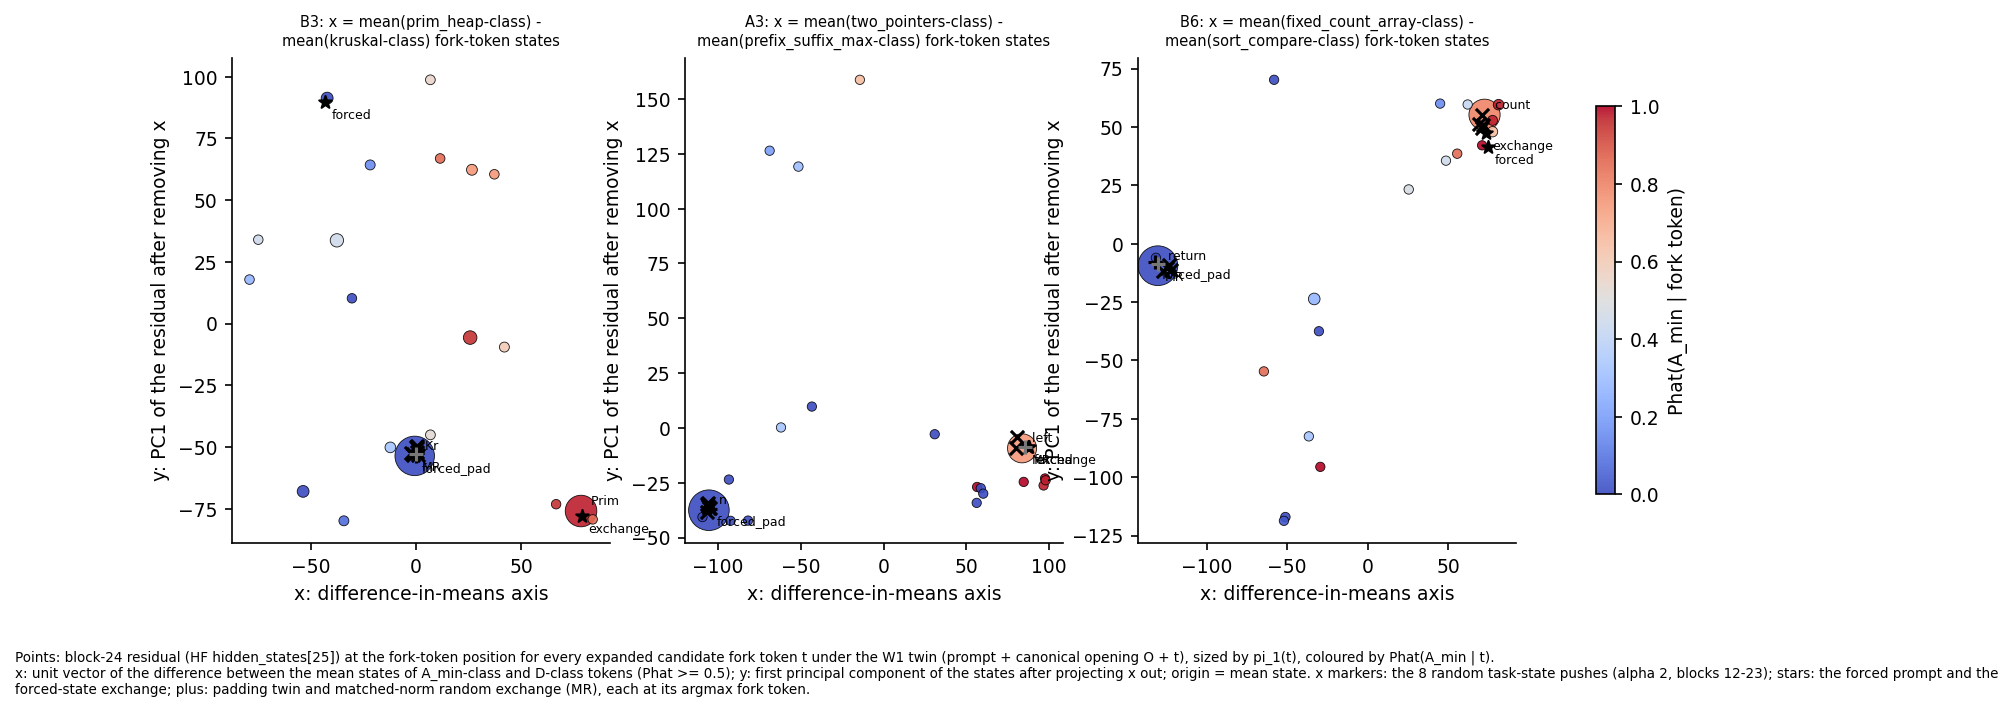

B3: extra states at their argmax fork token: forced| Check, forced_pad| Kr, exchange| Prim, MR| Kr
A3: extra states at their argmax fork token: forced| left, forced_pad| n, exchange| left, MR| left
B6: extra states at their argmax fork token: forced| count, forced_pad| return, exchange| count, MR| return


In [25]:
def decode_bf16(d: dict[str, Any]) -> np.ndarray:
    """notebook helper: the bf16 bits stored in mini_demo_data.json back to float32 (lossless)."""
    hi = np.frombuffer(base64.b64decode(d["b64"]), dtype="<u2").astype(np.uint32)
    return (hi << 16).view(np.float32).reshape(d["shape"])


# ---- src/figures7.py: f7_geometry (verbatim apart from the data source and a title line break) ----
def f7_geometry() -> None:
    R = meta["units"]                                              # was: read_json(PRED_DIR / "predictions_raw.json")
    units = [u for u in ("B3", "A3", "B6") if u in meta["geometry"]]   # was: (CACHE_DIR / f"geometry_{u}.npz").exists()
    if not units:
        return
    fig, axes = plt.subplots(1, len(units), figsize=(4.6 * len(units), 4.2), squeeze=False)
    for i, u in enumerate(units):
        ax = axes[0, i]
        G = meta["geometry"][u]                                    # was: z = np.load(CACHE_DIR / f"geometry_{u}.npz")
        z = {"X": decode_bf16(G["X"]), "toks": np.array(G["toks"]), "extra": decode_bf16(G["extra"]),
             "extra_names": np.array(G["extra_names"])}
        X, toks = z["X"].astype(np.float64), [int(t) for t in z["toks"]]
        E, En = z["extra"].astype(np.float64), [str(s) for s in z["extra_names"]]
        cid = sorted(R[u]["clusters"])[0]
        cl = R[u]["clusters"][cid]
        C, A, D = R[u]["cats"], R[u]["A_min"], R[u]["D"]
        ph = np.array([np.array(cl["counts"][str(t)], float)[C.index(A)] / max(1, sum(cl["counts"][str(t)]))
                       for t in toks])
        pd_ = np.array([np.array(cl["counts"][str(t)], float)[C.index(D)] / max(1, sum(cl["counts"][str(t)]))
                        for t in toks])
        pi = np.array([cl["pi1_avg"][str(t)] for t in toks])
        isA, isD = ph >= 0.5, pd_ >= 0.5
        mu = X.mean(0)
        if isA.any() and isD.any():
            ax_x = X[isA].mean(0) - X[isD].mean(0)
        else:
            ax_x = X[np.argmax(ph)] - X[np.argmin(ph)]
        ax_x /= np.linalg.norm(ax_x)
        Xc = X - mu
        xs = Xc @ ax_x
        Rr = Xc - np.outer(xs, ax_x)
        _, _, Vt = np.linalg.svd(Rr, full_matrices=False)
        ax_y = Vt[0]
        ys = Xc @ ax_y
        sc = ax.scatter(xs, ys, c=ph, cmap="coolwarm", vmin=0, vmax=1, s=20 + 400 * np.sqrt(pi), edgecolor="k",
                        lw=0.4, alpha=0.9)
        for t, x0, y0, p0 in zip(toks, xs, ys, pi):
            if p0 > 0.01:
                ax.annotate(repr(cl["tok_text"][str(t)])[1:-1][:9], (x0, y0), fontsize=6, xytext=(3, 3),
                            textcoords="offset points")
        if len(E):
            Ec = E - mu
            ex, ey = Ec @ ax_x, Ec @ ax_y
            for n_, x0, y0 in zip(En, ex, ey):
                kind = n_.split("|")[0]
                mk = "x" if kind.startswith("push") else ("*" if kind in ("exchange", "forced") else "+")
                ax.scatter([x0], [y0], marker=mk, color="k" if kind != "MR" else "#777777", s=40)
                if not kind.startswith("push"):
                    ax.annotate(kind, (x0, y0), fontsize=6, xytext=(3, -8), textcoords="offset points")
        ax.set_xlabel("x: difference-in-means axis")
        ax.set_ylabel("y: PC1 of the residual after removing x")
        ax.set_title(f"{u}: x = mean({A}-class) -\nmean({D}-class) fork-token states", fontsize=7)  # notebook: \n
    fig.colorbar(sc, ax=axes.ravel().tolist(), shrink=0.8, label="Phat(A_min | fork token)")
    fig.text(0.02, -0.06, "Points: block-24 residual (HF hidden_states[25]) at the fork-token position for every expanded "
             "candidate fork token t under the W1 twin (prompt + canonical opening O + t), sized by pi_1(t), coloured by "
             "Phat(A_min | t).\nx: unit vector of the difference between the mean states of A_min-class and D-class "
             "tokens (Phat >= 0.5); y: first principal component of the states after projecting x out; origin = mean "
             "state. x markers: the 8 random task-state pushes (alpha 2, blocks 12-23); stars: the forced prompt and the "
             "forced-state exchange; plus: padding twin and matched-norm random exchange (MR), each at its argmax fork "
             "token.", fontsize=6.5, va="top", wrap=True)
    save(fig, "F7_fork_geometry")


f7_geometry()
for u in MIXED:
    print(f"{u}: extra states at their argmax fork token:", ", ".join(meta["geometry"][u]["extra_names"][8:]))

## Results: predicted vs observed, the margins, and the demo beside the full run

**Top row: the committed prediction (line) against the observed minority share at each temperature.**
- Black dots are this demo's B3 programs (25 per temperature). Grey squares are the full run's 50 per cell, for all three units. The bars are Wilson 95% intervals.
- B3 follows the predicted collapse at low T. At T ≥ 1 its observed share sits above the prediction in both samples, more so on the demo's 25 slots.
- A3 and B6 are the units where Test 2 failed: A3 sits below its prediction at every T, and B6 shows no drop.

**Bottom: `f4_margins` from `src/figures7.py`.**
- **Left:** every fork margin. The mixed units' margins are recomputed here; the collapsed tasks' are committed.
- **Right:** the binary-fork off-default probability 1/(1 + e^{m/T}) for each margin. On the collapsed tasks the alternative stays out of reach at any temperature (at most about 2% at T 1.3, on T2).

**The final table** lists the headline numbers, this demo against the full run.

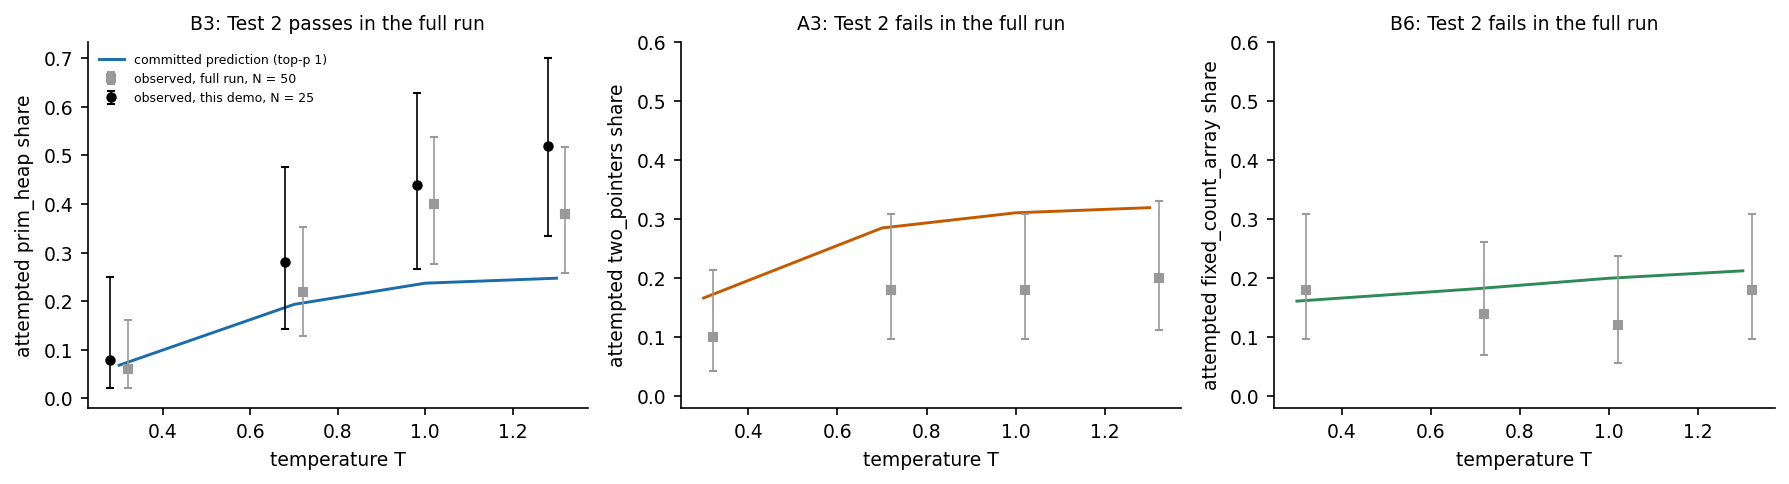

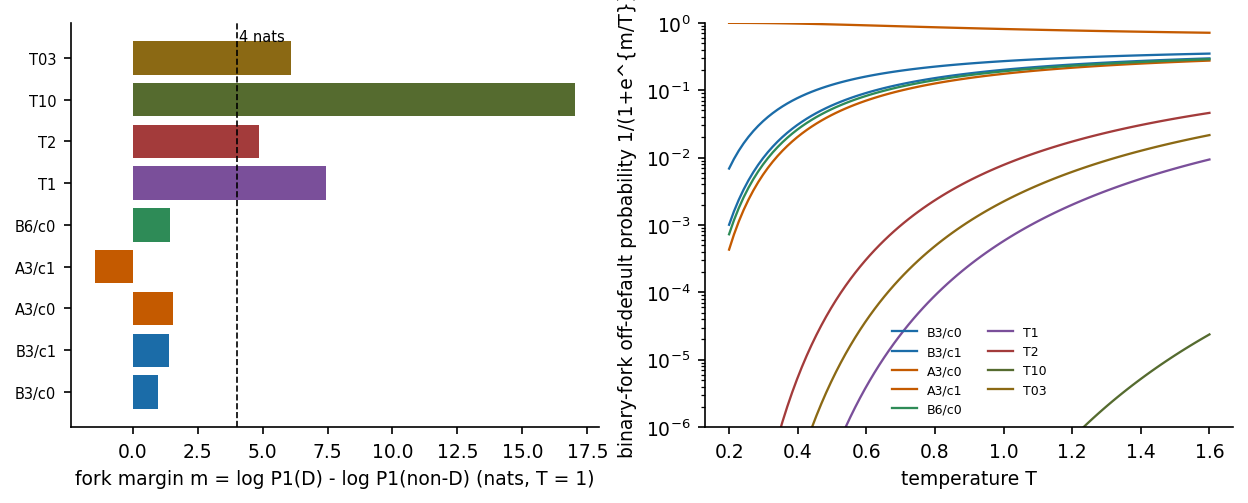

,this demo,full run
quantity,,
"Test 1: H(A | fork class), bits (B3 / A3 / B6)",0.050 / 0.153 / 0.189,0.050 / 0.153 / 0.189
confirmed on-opening forks at |O|+1 (B3 / A3 / B6),3/3 / 1/1 / 1/1,3/3 / 1/1 / 1/1
B3 observed Prim share at T 0.3 / 0.7 / 1.0 / 1.3,0.08 / 0.28 / 0.44 / 0.52,0.06 / 0.22 / 0.40 / 0.38
B3 committed prediction at T 0.3 / 0.7 / 1.0 / 1.3,0.068 / 0.193 / 0.237 / 0.247,0.068 / 0.193 / 0.237 / 0.247
"B3 drop T 1.0 -> 0.3 (exact McNemar b:c, p)","0.36 (9:0, p = 0.002)","0.34 (17:0, p = 7.6e-06)"
B3 MAE vs committed predictions,0.143 (4 cells),0.083 (8 cells)
B3 Test 2,fail,pass
fork-token replay names the algorithm (on-opening programs),82/85,0.90-0.98 of on-opening slots per cell
"Test 3: collapsed margins, nats (T1 / T2 / T10 / T03)",7.46 / 4.85 / 17.04 / 6.10,7.46 / 4.85 / 17.04 / 6.10


In [26]:
# ---- predicted vs observed (after f3_pred_vs_obs in src/figures7.py, with the demo's own observations added) ----
full_t2 = meta["full_run"]["test2"]["per_unit"]
fig, axes = plt.subplots(1, len(MIXED), figsize=(4.0 * len(MIXED), 3.3), squeeze=False)
for i, u in enumerate(MIXED):
    ax = axes[0, i]
    U = pv["units"][u]
    ax.plot(TEMPS, [U["cells"][f"T{T}_p1"]["a_min"] for T in TEMPS], "-", color=COL[u], lw=1.4,
            label="committed prediction (top-p 1)")
    for src, cells, fmt, colr, dx in (("full run, N = 50", full_t2[u]["cells"], "s", "#999999", 0.02),
                                      ("this demo", t2["per_unit"].get(u, {}).get("cells", {}), "o", "k", -0.02)):
        if not cells:
            continue
        obs = np.array([cells[f"T{T}_p1"]["a_min"] for T in TEMPS])
        lo = np.array([cells[f"T{T}_p1"]["a_min_ci"][0] for T in TEMPS])
        hi = np.array([cells[f"T{T}_p1"]["a_min_ci"][1] for T in TEMPS])
        n = cells[f"T{TEMPS[0]}_p1"]["n"]
        ax.errorbar(np.array(TEMPS) + dx, obs, yerr=[obs - lo, hi - obs], fmt=fmt, color=colr, ms=4, lw=0.8,
                    capsize=2, label=f"observed, {src}" + ("" if "N =" in src else f", N = {n}"))
    ax.set_xlabel("temperature T")
    ax.set_ylabel(f"attempted {U['A_min']} share")
    ax.set_title(f"{u}: Test 2 {'passes' if full_t2[u].get('pass') else 'fails'} in the full run", fontsize=9)
    ax.set_ylim(-0.02, max(0.6, ax.get_ylim()[1]))
    if i == 0:
        ax.legend(fontsize=6, frameon=False)
plt.tight_layout()
plt.show()


# ---- src/figures7.py: f4_margins (verbatim apart from the data source) ----
def f4_margins() -> None:
    # was: pv = read_json(RESULTS_DIR / "predictions_view.json") -- here the demo's view (recomputed margins)
    names, ms, cols = [], [], []
    for u, U in pv["units"].items():
        for cid, m in U["margins"].items():
            names.append(f"{u}/{cid}")
            ms.append(m["mean"])
            cols.append(COL[u])
    for t, c in pv.get("collapsed", {}).items():
        if t.startswith("_"):
            continue
        names.append(t)
        ms.append(c["margin_nats"] if math.isfinite(c["margin_nats"]) else 15.0)
        cols.append(COL.get(t, "#444444"))
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(10, 3.5))
    a1.barh(range(len(ms)), ms, color=cols)
    a1.set_yticks(range(len(ms)))
    a1.set_yticklabels(names, fontsize=7)
    a1.axvline(4.0, color="k", ls="--", lw=0.8)
    a1.text(4.1, len(ms) - 0.6, "4 nats", fontsize=7)
    a1.set_xlabel("fork margin m = log P1(D) - log P1(non-D) (nats, T = 1)")
    Ts = np.linspace(0.2, 1.6, 100)
    for n_, m, c in zip(names, ms, cols):
        a2.plot(Ts, [1 / (1 + math.exp(min(700, m / T))) for T in Ts], color=c, lw=1.1, label=n_)
    a2.set_yscale("log")
    a2.set_ylim(1e-6, 1)
    a2.set_xlabel("temperature T")
    a2.set_ylabel("binary-fork off-default probability 1/(1+e^{m/T})")
    a2.legend(fontsize=6, frameon=False, ncol=2)
    save(fig, "F4_margins")


f4_margins()

# ---- summary: this demo beside the full run ----
fr = meta["full_run"]
B, Bf = t2["per_unit"]["B3"], fr["test2"]["per_unit"]["B3"]
fmt3 = lambda xs: " / ".join(f"{x:.3f}" for x in xs)
fmt2 = lambda xs: " / ".join(f"{x:.2f}" for x in xs)
summary = [
    ("Test 1: H(A | fork class), bits (B3 / A3 / B6)", fmt3(t1["per_unit"][u]["H_bits"] for u in MIXED),
     fmt3(fr["test1"]["per_unit"][u]["H_bits"] for u in MIXED)),
    ("confirmed on-opening forks at |O|+1 (B3 / A3 / B6)",
     " / ".join(f"{forks_demo[u]['n_at_O_plus_1']}/{forks_demo[u]['n_confirmed_on_O']}" for u in MIXED),
     " / ".join(f"{F[u]['n_at_O_plus_1']}/{F[u]['n_confirmed_on_O']}" for u in MIXED)),
    ("B3 observed Prim share at T 0.3 / 0.7 / 1.0 / 1.3", fmt2(B["cells"][f"T{T}_p1"]["a_min"] for T in TEMPS),
     fmt2(Bf["cells"][f"T{T}_p1"]["a_min"] for T in TEMPS)),
    ("B3 committed prediction at T 0.3 / 0.7 / 1.0 / 1.3", fmt3(B["cells"][f"T{T}_p1"]["pred_a_min"] for T in TEMPS),
     fmt3(Bf["cells"][f"T{T}_p1"]["pred_a_min"] for T in TEMPS)),
    ("B3 drop T 1.0 -> 0.3 (exact McNemar b:c, p)",
     f"{B.get('delta_obs_10_03', float('nan')):.2f} ({B.get('mcnemar_b_10only')}:{B.get('mcnemar_c_03only')}, "
     f"p = {B.get('mcnemar_p_one_sided', float('nan')):.2g})",
     f"{Bf['delta_obs_10_03']:.2f} ({Bf['mcnemar_b_10only']}:{Bf['mcnemar_c_03only']}, "
     f"p = {Bf['mcnemar_p_one_sided']:.2g})"),
    ("B3 MAE vs committed predictions", f"{B.get('MAE', float('nan')):.3f} ({len(B['cells'])} cells)",
     f"{Bf['MAE']:.3f} (8 cells)"),
    ("B3 Test 2", "pass" if B.get("pass") else "fail", "pass" if Bf["pass"] else "fail"),
    ("fork-token replay names the algorithm (on-opening programs)",
     f"{int((on['replay predicts'] == on['label']).sum())}/{len(on)}",
     "0.90-0.98 of on-opening slots per cell"),
    ("Test 3: collapsed margins, nats (T1 / T2 / T10 / T03)", fmt2(t3["per_task"][t]["margin_nats"] for t in COLLAPSED),
     fmt2(fr["test3"]["per_task"][t]["margin_nats"] for t in COLLAPSED)),
    ("S4(b) fork-margin shift, exchange vs padding twin (A3 / B6), nats",
     fmt2(s4_demo[u]["exchange"]["exchange"]["d_margin_vs_pad"] for u in ("A3", "B6")),
     fmt2(fr["s4b"][u]["d_margin_exchange"] for u in ("A3", "B6"))),
    ("S4(b) minority share after the exchange (A3 / B6)", "(generation not run)",
     " / ".join(f"{fr['s4b'][u]['arms']['EXCH']['attempted_a_min']:.2f}" for u in ("A3", "B6"))),
    ("verdict", v["verdict"], fr["verdict"]["verdict"]),
]
display(pd.DataFrame(summary, columns=["quantity", "this demo", "full run"]).set_index("quantity"))

## What this demo reproduces, and how to run the full pipeline

**Re-computed here with the artifact's own code:**
- the CPU unit tests U4, U5, U7 and U8;
- every change point, confirmation and mode decision of the fork scan;
- H(A | fork class) with its bootstrap (Test 1);
- the fork margins and the top-k report;
- the S4(b) teacher-forced predictions for A3 and B6;
- a sha256 commitment of the predictions before scoring;
- the committed scoring of Tests 1–3, the verdict and the ideas × phrasings table, on 100 of the 1,200 sweep programs;
- figures F1, F2, F4 and F7.

**Loaded rather than recomputed:**
- the committed cell predictions and per-slot replays, whose full-vocabulary opening logits (`cache/tf/`) were removed after the round;
- the A3/B6 sweep shares, the S4 generation outcomes and the collapsed-task margins, from the full run's result files.

**Scaling back up.**
- The resampling depths in the config cell (`N_BOOT_H`, `N_BOOT_DROP`, `N_PERM`, `N_RUNS_U4`, `HILL1_*`) go up to their full-run values.
- **For the whole sweep** (1,200 programs: all three units, both samplers, slots 20–29):
  1. rebuild the data locally with `python build_mini_demo_data.py <experiment folder> mini_demo_data.json --full` (5.3 MB);
  2. set `N_SWEEP_SLOTS = 10` and `DEMO_SAMPLERS = {"p1": 0, "k10": 10}` in the config cell;
  3. make `load_data()` read that local file, for example by setting `GITHUB_DATA_URL = ""` in the data-loading cell.

  This path was checked end to end; it runs in about 15 s. At that size the notebook reproduces the full run's committed scoring exactly:
  - B3's Test 2: drop 0.34 [0.22, 0.48], McNemar 17:0 (p = 7.6e-6), MAE 0.083, pass;
  - the 1a–c table: Kruskal's phrasing clusters 4 → 6 → 10 → 12, Hill-1 1.25 → 1.69 → 1.95 → 1.92, idea changes on 20 of 50 slots;
  - the fork-token replay names the algorithm on 920 of 958 on-opening programs.
- The GPU stages need the artifact's repository, one CUDA GPU with ≥ 20 GB and about 0.75 GPU-hours:

```bash
uv venv .venv --python=3.12 && uv pip install --python .venv/bin/python -r pyproject.toml
.venv/bin/python src/download_models.py   # Qwen/Qwen3-8B@b968826d into the HF cache
.venv/bin/python method.py all            # vendor,prompts,gputests,twins,cputests,commit0,forkscan,
                                          # commit1,predict,commit2,generate,finalize
```

The blind judges in `finalize` also need `OPENROUTER_BASE_URL` and `OPENROUTER_API_KEY`.